# LLM grading of student texts: consolidated analysis

All analyses behind the figures of the paper, in one place. Raw results come from the experiment scripts
(`results/*.jsonl`); this notebook only reads them.

**Structure.** Each analysis follows the six-cells approach
([publication-ready plots guide](https://github.com/ahnt/publicationreadyplots)):
1. idea, 2. compute, 3. save the aggregated data (`analysis_data/`), 4. load, 5. plot and save the figure
(`paper/figures/`, PDF + EPS), 6. what the figure shows. To restyle a figure, jump to its load cell.

**Figure style.** 7.5 × 3 in (height in steps of 1.5 in), black first, then gray, red only if needed;
axis labels 16 pt, ticks 14 pt; no titles; panels labelled A), B), …; file names
`generalTitle_condition_maybeAxis`, no numbers or versions.

**Reference, not truth.** Neither the intended (generation) grades nor the expert's grades are a gold
standard; comparisons are reported as agreement and systematic differences.

In [1]:
import json
import pickle
import re
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()                      # run the notebook from the project folder
RESULTS = ROOT / "results"
DATA = ROOT / "analysis_data"          # aggregated data behind each figure
FIGS = ROOT / "paper" / "figures"      # publication figures (PDF + EPS)
DATA.mkdir(exist_ok=True)
FIGS.mkdir(parents=True, exist_ok=True)

GRADES = ["F", "E", "D", "C", "B", "A"]
NUM = {g: i for i, g in enumerate(GRADES)}

# style (publication-ready plots guide)
FIGSIZE = (7.5, 3.0)
LABEL, TICK = 16, 14
BLACK, GRAY, LIGHT, RED = "k", "0.55", "0.8", "#FF4422"
plt.rcParams.update({"font.family": "sans-serif", "pdf.fonttype": 42, "ps.fonttype": 42})

KEY = json.load(open(ROOT / "texts" / "texts_key.json", encoding="utf-8"))   # intended grades
INTENDED = {t: NUM[k["intended_grade"]] for t, k in KEY.items()}


def save_figure(fig, name):
    """Save as PDF and EPS in paper/figures (no raster formats)."""
    fig.tight_layout()
    for ext in ("pdf", "eps"):
        fig.savefig(FIGS / f"{name}.{ext}")
    print("saved", FIGS / f"{name}.pdf")


def jitter(values, width, seed=1):
    rng = np.random.default_rng(seed)
    return np.asarray(values, dtype=float) + rng.uniform(-width, width, len(values))


def single_grade(record):
    """Grade of a single-text call; a garbled student code is still unambiguous with one text."""
    g = record.get("grade")
    if g in NUM:
        return g
    s = (record.get("students") or [{}])[0]
    g = s.get("grade")
    if g in NUM:
        return g
    try:
        g = json.loads(record.get("raw") or "")["bedomningar"][0]["betyg"]
    except (json.JSONDecodeError, KeyError, IndexError, TypeError):
        return None
    return g if g in NUM else None

## 1. Single-text grading: intended grade vs. model grade

**Idea.** Before any context effects: how does each model grade a text on its own (fresh context, one
text per prompt)? One point per text: x = intended (generation) grade, y = the model's mean grade over
its repeated runs; with and without the task-specific criteria.

Sources: local models from the anonymous rounds on the inferno cluster (label "Elev 1", 3 runs each);
commercial models from the OpenRouter runs (random anonymisation codes, 2 runs each). The label format
changes single grades only within run-to-run noise (checked for gemma4: same rounded grade for 90%).

In [2]:
# 2) compute: one row per (model, criteria, text) with the mean grade over runs
SINGLE_SOURCES = {
    "gemma4:26b":            ("anon_inferno_gemma4-26b_nothink.jsonl", "anon"),
    "qwen3:30b-a3b":         ("anon_inferno_qwen3-30b-a3b_think-off.jsonl", "anon"),
    "gpt-6-luna":            ("or_ormain_openai-gpt-6-luna.jsonl", "openrouter"),
    "gemini-3.1-flash-lite": ("or_ormain_google-gemini-3.1-flash-lite.jsonl", "openrouter"),
}

rows = []
for model, (fname, kind) in SINGLE_SOURCES.items():
    runs = defaultdict(list)
    for line in open(RESULTS / fname, encoding="utf-8"):
        r = json.loads(line)
        if kind == "openrouter" and (r.get("error") is not None or r["design"] != "single_code"):
            continue
        g = single_grade(r)
        if g is None:
            continue
        tid = r["text_id"] if kind == "anon" else r["students"][0]["text_id"]
        runs[(r["criteria"], tid)].append(NUM[g])
    for (crit, tid), gs in runs.items():
        rows.append({"model": model, "criteria": crit, "text_id": tid, "intended": INTENDED[tid],
                     "grade_mean": np.mean(gs), "n_runs": len(gs)})
single = pd.DataFrame(rows)
single.groupby(["model", "criteria"]).agg(texts=("text_id", "nunique"), runs=("n_runs", "mean"))

texts  runs
model                 criteria             
gemini-3.1-flash-lite False       720   2.0
                      True        720   2.0
gemma4:26b            False       720   3.0
                      True        720   3.0
gpt-6-luna            False       720   2.0
                      True        720   2.0
qwen3:30b-a3b         False       720   3.0
                      True        720   3.0

In [3]:
# 3) save
single.to_pickle(DATA / "single_intended_vs_model.pkl")

In [4]:
# 4) load
single = pd.read_pickle(DATA / "single_intended_vs_model.pkl")

saved paper/figures/Scatter_intendedVsModelGrade_gemma4-26b.pdf


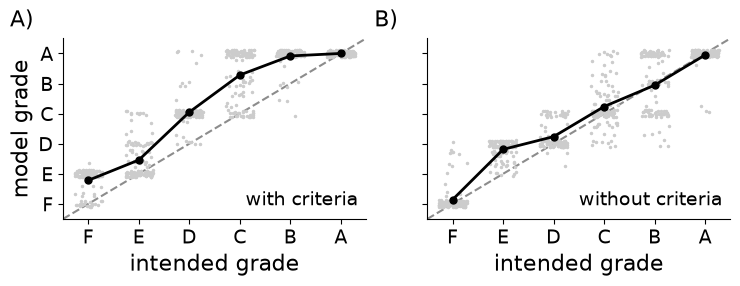

saved paper/figures/Scatter_intendedVsModelGrade_qwen3-30b-a3b.pdf


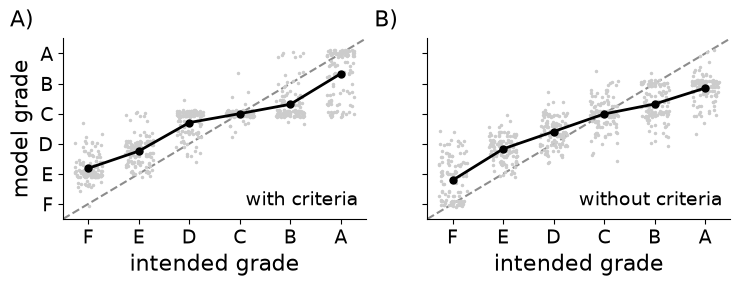

saved paper/figures/Scatter_intendedVsModelGrade_gpt-6-luna.pdf


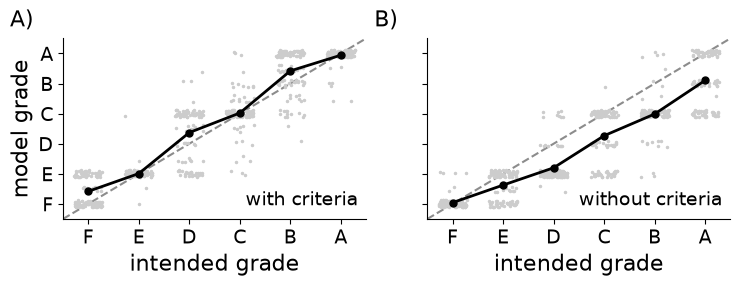

saved paper/figures/Scatter_intendedVsModelGrade_gemini-3.1-flash-lite.pdf


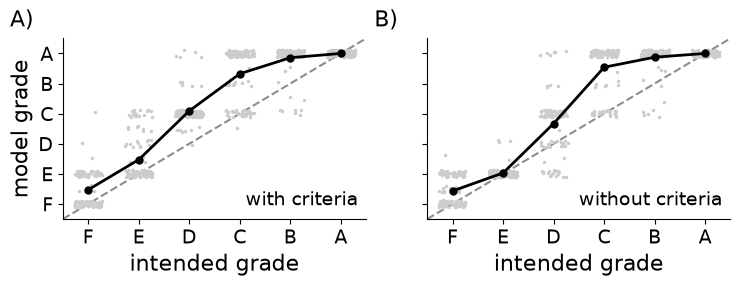

In [5]:
# 5) plot: one figure per model, A) with criteria, B) without criteria
def plot_single_scatter(model):
    fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, sharey=True)
    for i, (ax, crit, label) in enumerate(zip(axes, (True, False), ("A)", "B)"))):
        d = single[(single.model == model) & (single.criteria == crit)]
        ax.plot([-0.5, 5.5], [-0.5, 5.5], "--", color=GRAY, linewidth=1.5, zorder=1)           # agreement
        ax.plot(jitter(d.intended, 0.28), jitter(d.grade_mean, 0.12, seed=2), ".", color=LIGHT,
                markersize=3, zorder=2)                     # one text (opaque: EPS has no transparency)
        m = d.groupby("intended").grade_mean.mean()
        ax.plot(m.index, m.values, "-o", color=BLACK, linewidth=2.0, markersize=5, zorder=3)     # mean
        ax.set_xlim(-0.5, 5.5)
        ax.set_ylim(-0.5, 5.5)
        ax.set_xticks(range(6), GRADES, fontsize=TICK)
        ax.set_xlabel("intended grade", fontsize=LABEL)
        if i == 0:
            ax.set_ylabel("model grade", fontsize=LABEL)
            ax.set_yticks(range(6), GRADES, fontsize=TICK)
        else:
            ax.tick_params(axis="y", labelsize=0)
        ax.text(5.35, -0.2, "with criteria" if crit else "without criteria", fontsize=TICK,
                ha="right", va="bottom")
        ax.text(-1.55, 5.9, label, fontsize=LABEL)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    save_figure(fig, f"Scatter_intendedVsModelGrade_{model.replace(':', '-')}")
    plt.show()


for model in SINGLE_SOURCES:
    plot_single_scatter(model)

In [6]:
# numbers for the summary: Pearson r (per text), mean shift (model - intended), exact agreement of rounded means
def summarize(d):
    return pd.Series({"r": np.corrcoef(d.intended, d.grade_mean)[0, 1],
                      "shift": (d.grade_mean - d.intended).mean(),
                      "exact": (d.grade_mean.round() == d.intended).mean(),
                      "texts": len(d)})

single.groupby(["model", "criteria"]).apply(summarize, include_groups=False).round(2)

r  shift  exact  texts
model                 criteria                           
gemini-3.1-flash-lite False     0.91   0.59   0.51  720.0
                      True      0.91   0.70   0.44  720.0
gemma4:26b            False     0.93   0.22   0.61  720.0
                      True      0.92   0.75   0.37  720.0
gpt-6-luna            False     0.90  -0.63   0.44  720.0
                      True      0.94   0.20   0.63  720.0
qwen3:30b-a3b         False     0.87   0.03   0.39  720.0
                      True      0.89   0.21   0.38  720.0

**6) What the figures show.**

- **All models rank the texts like the intended grades** (r = 0.86–0.94 per text). Differences are in
  calibration and in how the scale is used, not in the ordering.
- **Mean shift vs. intended grade** (with / without criteria): gemma4 +0.75 / +0.22, gemini +0.70 / +0.59,
  gpt-6-luna +0.20 / −0.63, qwen3 +0.21 / +0.03. The intended grades are not a gold
  standard: the expert rater is about +0.5 grade above them (section on the expert rating), so positive
  shifts partly reflect the stricter generation calibration.
- **Criteria change the calibration**, in different directions per model: gemma4 and luna move up with
  criteria, luna without criteria is strict.
- **Scale use:** with criteria, gemma4's points pile up at E, C and A (plateaus in panel A); intermediate
  grades D and B are rarely given. qwen3 compresses the upper end (A texts often below B).

## 2. Single-text grading: expert rater as reference

**Idea.** Same single-text grades as in section 1, now compared with the blind grades of the expert rater
(German-as-a-second-language specialist) on a stratified sample of 144 texts (2 per intended grade per
assignment). One point per text: x = expert grade, y = intended grade (panel A) or the model's mean grade
with (B) and without (C) criteria. Texts the expert flagged as unrealistic are ringed.

The expert is one rater with her own calibration, not a gold standard; agreement is reported as exact
agreement, agreement within one grade step, mean difference, and quadratic weighted kappa (QWK) over all
individual gradings.

In [7]:
# 2) compute: expert grades, flagged texts, and every rater's individual gradings on the expert's texts
EXPERT_FILE = ROOT / "ratings" / "backups" / "leonie_FINAL_20260927_1527.json"   # read-only snapshot
expert_state = json.load(open(EXPERT_FILE, encoding="utf-8"))
expert = {t: NUM[v["grade"]] for t, v in expert_state["ratings"].items() if v.get("grade") in NUM}
flagged = sorted(t for t, v in expert_state["ratings"].items() if v.get("flag"))

rater_runs = {("intended", None): {t: [INTENDED[t]] for t in expert}}
for model, (fname, kind) in SINGLE_SOURCES.items():
    for crit in (True, False):
        rater_runs[(model, crit)] = defaultdict(list)
    for line in open(RESULTS / fname, encoding="utf-8"):
        r = json.loads(line)
        if kind == "openrouter" and (r.get("error") is not None or r["design"] != "single_code"):
            continue
        g = single_grade(r)
        tid = r["text_id"] if kind == "anon" else r["students"][0]["text_id"]
        if g is not None and tid in expert:
            rater_runs[(model, r["criteria"])][tid].append(NUM[g])

rows = [{"rater": m, "criteria": c, "text_id": t, "expert": expert[t], "grade_mean": np.mean(gs),
         "runs": gs, "flagged": t in flagged}
        for (m, c), by in rater_runs.items() for t, gs in by.items()]
vs_expert = pd.DataFrame(rows)
print(len(expert), "texts graded by the expert,", len(flagged), "flagged:", flagged)

144 texts graded by the expert, 3 flagged: ['G6-3-T53', 'G7-1-T02', 'G7-3-T11']


In [8]:
# 3) save
vs_expert.to_pickle(DATA / "single_vs_expert.pkl")

In [9]:
# 4) load
vs_expert = pd.read_pickle(DATA / "single_vs_expert.pkl")

saved paper/figures/Scatter_expertVsGrade_gemma4-26b.pdf


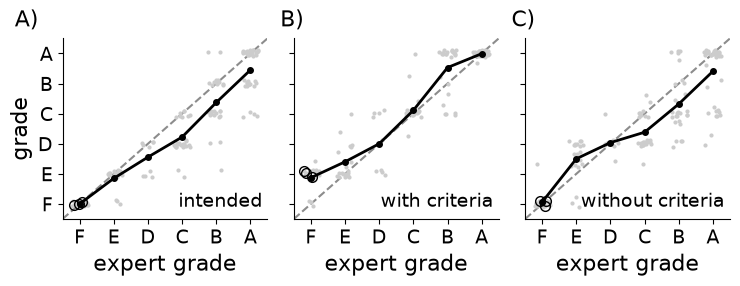

saved paper/figures/Scatter_expertVsGrade_qwen3-30b-a3b.pdf


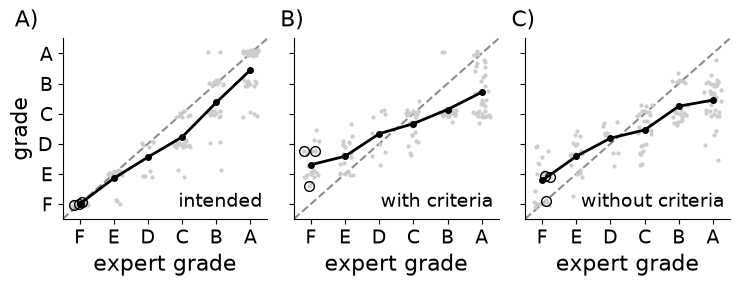

saved paper/figures/Scatter_expertVsGrade_gpt-6-luna.pdf


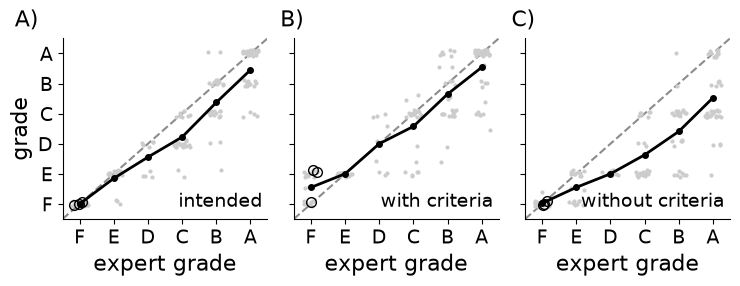

saved paper/figures/Scatter_expertVsGrade_gemini-3.1-flash-lite.pdf


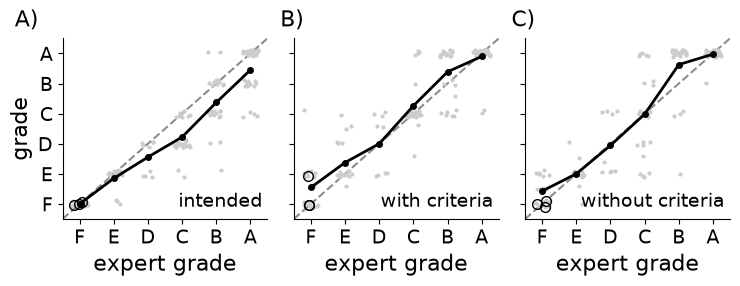

In [10]:
# 5) plot: one figure per model; A) intended grade, B) model with criteria, C) model without criteria
def scatter_panel(ax, d, label, note, first):
    ax.plot([-0.5, 5.5], [-0.5, 5.5], "--", color=GRAY, linewidth=1.5, zorder=1)
    x, y = jitter(d.expert, 0.25, seed=3), jitter(d.grade_mean, 0.12, seed=4)
    ax.plot(x, y, ".", color=LIGHT, markersize=4, zorder=2)
    ring = d.flagged.values
    ax.plot(x[ring], y[ring], "o", markerfacecolor="none", markeredgecolor=BLACK, markersize=7,
            markeredgewidth=1.0, zorder=4)
    m = d.groupby("expert").grade_mean.mean()
    ax.plot(m.index, m.values, "-o", color=BLACK, linewidth=2.0, markersize=4, zorder=3)
    ax.set_xlim(-0.5, 5.5)
    ax.set_ylim(-0.5, 5.5)
    ax.set_xticks(range(6), GRADES, fontsize=TICK)
    ax.set_xlabel("expert grade", fontsize=LABEL)
    if first:
        ax.set_ylabel("grade", fontsize=LABEL)
        ax.set_yticks(range(6), GRADES, fontsize=TICK)
    else:
        ax.tick_params(axis="y", labelsize=0)
    ax.text(5.35, -0.25, note, fontsize=TICK, ha="right", va="bottom")
    ax.text(-1.9 if first else -0.9, 5.9, label, fontsize=LABEL)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


def plot_vs_expert(model):
    fig, axes = plt.subplots(1, 3, figsize=FIGSIZE, sharey=True)
    panels = [(("intended", None), "A)", "intended"),
              ((model, True), "B)", "with criteria"),
              ((model, False), "C)", "without criteria")]
    for i, (ax, (key, label, note)) in enumerate(zip(axes, panels)):
        d = vs_expert[(vs_expert.rater == key[0]) & (vs_expert.criteria.isna() if key[1] is None
                                                     else vs_expert.criteria == key[1])]
        scatter_panel(ax, d, label, note, i == 0)
    save_figure(fig, f"Scatter_expertVsGrade_{model.replace(':', '-')}")
    plt.show()


for model in SINGLE_SOURCES:
    plot_vs_expert(model)

saved paper/figures/Scatter_expertVsGrade_allRaters_withCriteria.pdf


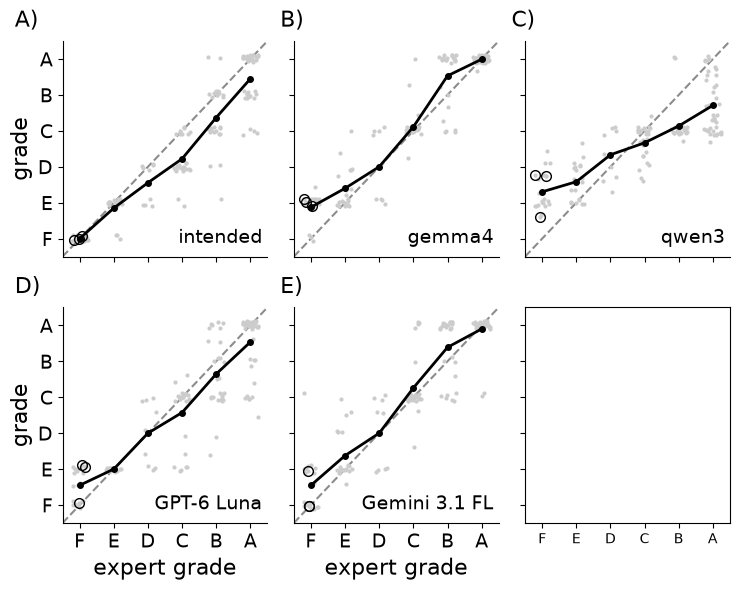

saved paper/figures/Scatter_expertVsGrade_allRaters_withoutCriteria.pdf


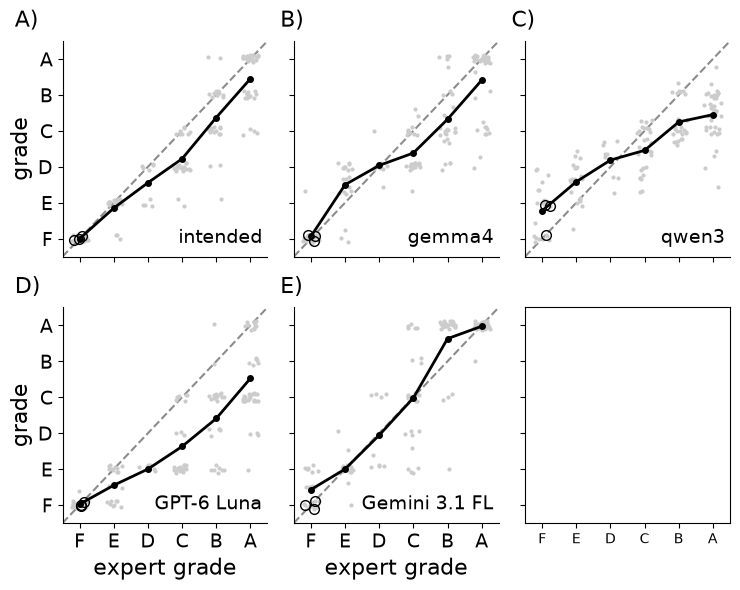

In [11]:
# 5b) combined figure for the paper: all raters with criteria, 3 x 2 panels (3 in per row)
SHORT = {"intended": "intended", "gemma4:26b": "gemma4", "qwen3:30b-a3b": "qwen3",
         "gpt-6-luna": "GPT-6 Luna", "gemini-3.1-flash-lite": "Gemini 3.1 FL"}


def plot_vs_expert_all(crit=True):
    fig, axes = plt.subplots(2, 3, figsize=(7.5, 6.0), sharex=True, sharey=True)
    raters = [("intended", None)] + [(m, crit) for m in SINGLE_SOURCES]
    for i, (ax, (rater, c)) in enumerate(zip(axes.flat, raters)):
        d = vs_expert[(vs_expert.rater == rater) & (vs_expert.criteria.isna() if c is None else vs_expert.criteria == c)]
        scatter_panel(ax, d, "ABCDEF"[i] + ")", SHORT[rater], i % 3 == 0)
        if i < 3:                      # x labels only on the bottom row
            ax.set_xlabel("")
            ax.tick_params(axis="x", labelsize=0)
    save_figure(fig, f"Scatter_expertVsGrade_allRaters_{'withCriteria' if crit else 'withoutCriteria'}")
    plt.show()


plot_vs_expert_all(True)
plot_vs_expert_all(False)

In [12]:
# agreement with the expert over all individual gradings (models: every run counts)
def qwk(a, b, k=6):
    a, b = np.asarray(a), np.asarray(b)
    obs = np.zeros((k, k))
    np.add.at(obs, (a, b), 1)
    w = (np.arange(k)[:, None] - np.arange(k)[None, :]) ** 2
    exp = np.outer(obs.sum(1), obs.sum(0)) / obs.sum()
    return 1 - (w * obs).sum() / (w * exp).sum()


def agreement(d):
    pairs = [(g, e) for gs, e in zip(d.runs, d.expert) for g in gs]
    g, e = np.array(pairs).T
    return pd.Series({"gradings": len(g), "exact": np.mean(g == e), "within_1": np.mean(abs(g - e) <= 1),
                      "mean_diff": np.mean(g - e), "QWK": qwk(g, e)})


table = (vs_expert.assign(criteria=vs_expert.criteria.map({True: "with", False: "without"}).fillna("-"))
         .groupby(["rater", "criteria"]).apply(agreement, include_groups=False))
print("all texts"); display(table.round(2))
print("without the flagged texts"); display(
    vs_expert[~vs_expert.flagged].assign(criteria=lambda x: x.criteria.map({True: "with", False: "without"}).fillna("-"))
    .groupby(["rater", "criteria"]).apply(agreement, include_groups=False).round(2))

all texts


gradings  exact  within_1  mean_diff   QWK
rater                 criteria                                            
gemini-3.1-flash-lite with         288.0   0.60      0.93       0.23  0.90
                      without      288.0   0.58      0.90       0.17  0.89
gemma4:26b            with         432.0   0.58      0.98       0.30  0.92
                      without      432.0   0.51      0.89      -0.33  0.86
gpt-6-luna            with         288.0   0.59      0.90      -0.19  0.88
                      without      288.0   0.37      0.62      -1.09  0.66
intended              -            144.0   0.58      0.94      -0.47  0.90
qwen3:30b-a3b         with         432.0   0.29      0.78      -0.29  0.70
                      without      432.0   0.31      0.80      -0.47  0.70

without the flagged texts


gradings  exact  within_1  mean_diff   QWK
rater                 criteria                                            
gemini-3.1-flash-lite with         282.0   0.60      0.93       0.22  0.89
                      without      282.0   0.57      0.89       0.17  0.88
gemma4:26b            with         423.0   0.59      0.98       0.29  0.92
                      without      423.0   0.50      0.89      -0.33  0.85
gpt-6-luna            with         282.0   0.60      0.90      -0.21  0.87
                      without      282.0   0.35      0.61      -1.11  0.65
intended              -            141.0   0.57      0.94      -0.48  0.89
qwen3:30b-a3b         with         423.0   0.29      0.79      -0.33  0.69
                      without      423.0   0.31      0.79      -0.49  0.68

**6) What the figures show.**

- **Intended grades vs. expert (panel A):** same ranking (QWK 0.90), but the expert grades about half a
  grade higher (mean difference −0.47 for the intended grades), mostly from D upward. This is a difference
  in calibration between the text generation and the expert, not an error on either side.
- **Models closest to the expert, graded alone with criteria:** gemma4 (QWK 0.92, 98 % within one step,
  +0.30), gemini-3.1-flash-lite (0.90, +0.23), gpt-6-luna (0.88, −0.19). qwen3 agrees clearly
  less (QWK 0.70) and grades lower than the expert (−0.3 to −0.5).
- **Criteria matter for some models:** gemma4 0.86 → 0.92 with criteria; gpt-6-luna without criteria is
  much stricter than the expert (−1.09, QWK 0.66); qwen3 is unaffected.
- **Typical deviations (panels B, C):** with criteria gemma4 lifts the expert's F texts to E and B texts
  to A; qwen3 flattens the upper end (expert A → model B/C).
- **Flagged texts (rings):** 3 of 144, all of the F subtype "single words strung together"; excluding them
  changes no statistic by more than 0.02.

## 2b. Agreement statistics with confidence intervals (SI table)

**Idea.** Every rater graded alone is compared with two references: the intended grades (all 720 texts) and
the expert's grades (144 texts). The expert is also compared with the intended grades. Every individual run
counts. Measures: quadratic weighted kappa (QWK; 0 = agreement expected by chance, 1 = perfect agreement,
larger disagreements weigh more), exact agreement, agreement within one grade, and mean difference
(rater − reference, in grades). 95 % confidence intervals from 2,000 bootstrap samples over texts (all runs
of a text are resampled together). A QWK interval far above 0 means agreement well beyond chance; a mean
difference interval that excludes 0 means a systematic calibration difference. Neither reference is a gold
standard.

In [13]:
# 2) compute: individual gradings per text for every rater, statistics with bootstrap CIs over texts
MODEL_LABEL = {"gemma4:26b": "gemma4", "qwen3:30b-a3b": "qwen3",
               "gpt-6-luna": "Luna", "gemini-3.1-flash-lite": "Gemini"}
runs_all = {}
for model, (fname, kind) in SINGLE_SOURCES.items():
    for crit in (True, False):
        runs_all[(MODEL_LABEL[model], crit)] = defaultdict(list)
    for line in open(RESULTS / fname, encoding="utf-8"):
        r = json.loads(line)
        if kind == "openrouter" and (r.get("error") is not None or r["design"] != "single_code"):
            continue
        g = single_grade(r)
        if g is not None:
            tid = r["text_id"] if kind == "anon" else r["students"][0]["text_id"]
            runs_all[(MODEL_LABEL[model], r["criteria"])][tid].append(NUM[g])


def agreement_stats(pairs):
    g = np.concatenate([p[0] for p in pairs])
    e = np.concatenate([p[1] for p in pairs])
    return {"exact": np.mean(g == e), "within_1": np.mean(abs(g - e) <= 1), "mean_diff": np.mean(g - e),
            "QWK": qwk(g, e)}


def agreement_ci(runs, reference, n_boot=2000, seed=1):
    texts = sorted(t for t in runs if t in reference)
    pairs = [(np.array(runs[t]), np.full(len(runs[t]), reference[t])) for t in texts]
    point = agreement_stats(pairs)
    rng = np.random.default_rng(seed)
    boot = pd.DataFrame([agreement_stats([pairs[i] for i in rng.integers(0, len(pairs), len(pairs))])
                         for _ in range(n_boot)])
    row = {"texts": len(texts), "gradings": sum(len(p[0]) for p in pairs)}
    for k, v in point.items():
        row[k] = v
        row[k + "_lo"], row[k + "_hi"] = np.percentile(boot[k], [2.5, 97.5])
    return row


agree_rows = [{"rater": "expert", "criteria": None, "reference": "intended",
               **agreement_ci({t: [g] for t, g in expert.items()}, INTENDED)}]
for (label, crit), runs in runs_all.items():
    for ref_name, ref in (("intended", INTENDED), ("expert", expert)):
        agree_rows.append({"rater": label, "criteria": crit, "reference": ref_name, **agreement_ci(runs, ref)})
agreement_table = pd.DataFrame(agree_rows)
agreement_table.round(2)

,rater,criteria,reference,texts,gradings,exact,exact_lo,exact_hi,within_1,within_1_lo,within_1_hi,mean_diff,mean_diff_lo,mean_diff_hi,QWK,QWK_lo,QWK_hi
0,expert,None,intended,144,144,0.58,0.50,0.66,0.94,0.90,0.97,0.47,0.36,0.57,0.90,0.86,0.93
1,gemma4,True,intended,720,2160,0.37,0.34,0.41,0.88,0.85,0.90,0.75,0.70,0.80,0.84,0.82,0.86
2,gemma4,True,expert,144,432,0.58,0.50,0.66,0.98,0.95,1.00,0.30,0.20,0.40,0.92,0.90,0.94
3,gemma4,False,intended,720,2160,0.61,0.57,0.64,0.96,0.95,0.98,0.22,0.17,0.26,0.91,0.90,0.92
4,gemma4,False,expert,144,432,0.51,0.43,0.59,0.89,0.84,0.94,-0.33,-0.46,-0.19,0.86,0.80,0.90
5,qwen3,True,intended,720,2160,0.39,0.36,0.42,0.90,0.88,0.92,0.21,0.15,0.28,0.79,0.77,0.81
6,qwen3,True,expert,144,432,0.29,0.23,0.36,0.78,0.72,0.84,-0.29,-0.47,-0.12,0.70,0.64,0.74
7,qwen3,False,intended,720,2160,0.38,0.35,0.41,0.90,0.88,0.91,0.03,-0.04,0.09,0.78,0.76,0.80
8,qwen3,False,expert,144,432,0.31,0.25,0.37,0.80,0.74,0.85,-0.47,-0.64,-0.29,0.70,0.62,0.76
9,Luna,True,intended,720,1440,0.61,0.58,0.65,0.97,0.96,0.98,0.20,0.15,0.24,0.92,0.91,0.93


In [14]:
# 3) save
agreement_table.to_pickle(DATA / "agreement_ci.pkl")

In [15]:
# 4) load
agreement_table = pd.read_pickle(DATA / "agreement_ci.pkl")

In [16]:
# 5) SI table (LaTeX): one row per rater and criteria condition, both references side by side
TABLES = ROOT / "paper" / "tables"
TABLES.mkdir(exist_ok=True)


def ci(r, k, signed=False):
    f = "{:+.2f}" if signed else "{:.2f}"
    return f"{f.format(r[k])} [{f.format(r[k + '_lo'])}, {f.format(r[k + '_hi'])}]"


order = ["expert", "gemma4", "qwen3", "Luna", "Gemini"]
lines = [r"\begin{tabular}{llcccccc}", r"\toprule",
         r" & & \multicolumn{2}{c}{vs.\ intended grade (720 texts)} & \multicolumn{4}{c}{vs.\ expert grade (144 texts)} \\",
         r"\cmidrule(lr){3-4}\cmidrule(lr){5-8}",
         r"Rater & Criteria & QWK & Mean diff. & QWK & Exact & Within 1 & Mean diff. \\", r"\midrule"]
for rater in order:
    for crit in ([None] if rater == "expert" else [False, True]):
        sel = agreement_table[(agreement_table.rater == rater)
                              & (agreement_table.criteria.isna() if crit is None else agreement_table.criteria == crit)]
        vi = sel[sel.reference == "intended"].iloc[0]
        cells = [rater, "--" if crit is None else ("with" if crit else "without"), ci(vi, "QWK"), ci(vi, "mean_diff", True)]
        ve = sel[sel.reference == "expert"]
        if len(ve):
            ve = ve.iloc[0]
            cells += [ci(ve, "QWK"), f"{ve.exact:.2f}", f"{ve.within_1:.2f}", ci(ve, "mean_diff", True)]
        else:
            cells += ["--"] * 4
        lines.append(" & ".join(cells) + r" \\")
lines += [r"\bottomrule", r"\end{tabular}"]
(TABLES / "Table_agreementTests.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("saved", TABLES / "Table_agreementTests.tex")
print("\n".join(lines))

saved paper/tables/Table_agreementTests.tex
\begin{tabular}{llcccccc}
\toprule
 & & \multicolumn{2}{c}{vs.\ intended grade (720 texts)} & \multicolumn{4}{c}{vs.\ expert grade (144 texts)} \\
\cmidrule(lr){3-4}\cmidrule(lr){5-8}
Rater & Criteria & QWK & Mean diff. & QWK & Exact & Within 1 & Mean diff. \\
\midrule
expert & -- & 0.90 [0.86, 0.93] & +0.47 [+0.36, +0.57] & -- & -- & -- & -- \\
gemma4 & without & 0.91 [0.90, 0.92] & +0.22 [+0.17, +0.26] & 0.86 [0.80, 0.90] & 0.51 & 0.89 & -0.33 [-0.46, -0.19] \\
gemma4 & with & 0.84 [0.82, 0.86] & +0.75 [+0.70, +0.80] & 0.92 [0.90, 0.94] & 0.58 & 0.98 & +0.30 [+0.20, +0.40] \\
qwen3 & without & 0.78 [0.76, 0.80] & +0.03 [-0.04, +0.09] & 0.70 [0.62, 0.76] & 0.31 & 0.80 & -0.47 [-0.64, -0.29] \\
qwen3 & with & 0.79 [0.77, 0.81] & +0.21 [+0.15, +0.28] & 0.70 [0.64, 0.74] & 0.29 & 0.78 & -0.29 [-0.47, -0.12] \\
Luna & without & 0.82 [0.80, 0.84] & -0.63 [-0.68, -0.58] & 0.66 [0.58, 0.73] & 0.37 & 0.62 & -1.09 [-1.25, -0.93] \\
Luna & with & 0.92

**6) What the table shows.**

- **Expert vs. intended:** QWK 0.90 [0.86, 0.93], far above chance; the expert grades higher by +0.47
  [+0.36, +0.57] grades, a systematic calibration difference.
- **Models vs. intended:** all well above chance (QWK 0.78–0.92).
- **Models vs. expert, with criteria:** gemma4 0.92 [0.90, 0.94], Gemini 0.90 [0.86, 0.93], Luna 0.88
  [0.83, 0.91], intervals overlapping the expert–intended agreement; qwen3 0.70, interval
  clearly below. Mean differences to the expert are small but systematic (+0.30, +0.23, −0.19).
- **The reference changes the picture:** with criteria, gemma4 agrees best with the expert (0.92) but less
  with the intended grades (0.84), because it shifts upward like the expert. Luna without criteria is the
  opposite case (strict: −1.09 vs. expert). This is why neither reference is treated as correct.

## 3. Overview figure: intended grade vs. expert and vs. all models

**Idea.** One row that summarises sections 1 and 2: A) how the expert grades the texts relative to their
intended grade (144 texts, points + mean), B) and C) the mean grade of every model per intended grade
(all 720 texts, graded alone), without and with criteria. Lines only; local models in grayscale, commercial
models in red/blue; marker shapes distinguish models without colour.

Uses the data of sections 1 and 2 (no new computation).

saved paper/figures/Lines_intendedVsGrade_expertAndModels.pdf


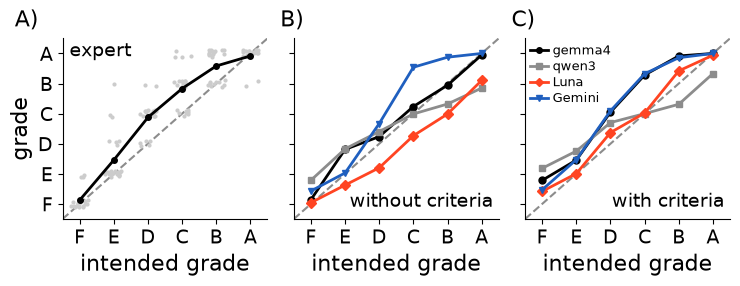

In [17]:
# 5) plot
LINE_STYLE = {  # model: (color, marker)
    "gemma4:26b": (BLACK, "o"), "qwen3:30b-a3b": (GRAY, "s"),
    "gpt-6-luna": (RED, "D"), "gemini-3.1-flash-lite": ("#1f5fbf", "v"),
}
LEGEND_NAME = {"gemma4:26b": "gemma4", "qwen3:30b-a3b": "qwen3",
               "gpt-6-luna": "Luna", "gemini-3.1-flash-lite": "Gemini"}


def model_lines(ax, crit):
    for model, (color, marker) in LINE_STYLE.items():
        m = single[(single.model == model) & (single.criteria == crit)].groupby("intended").grade_mean.mean()
        ax.plot(m.index, m.values, "-", marker=marker, color=color, linewidth=2.0, markersize=5,
                label=LEGEND_NAME[model], zorder=3)


fig, axes = plt.subplots(1, 3, figsize=FIGSIZE, sharey=True)
# A) intended vs. expert
d = vs_expert[vs_expert.rater == "intended"]
ax = axes[0]
ax.plot([-0.5, 5.5], [-0.5, 5.5], "--", color=GRAY, linewidth=1.5, zorder=1)
ax.plot(jitter(d.grade_mean, 0.25, seed=5), jitter(d.expert, 0.12, seed=6), ".", color=LIGHT, markersize=4, zorder=2)
m = d.groupby("grade_mean").expert.mean()
ax.plot(m.index, m.values, "-o", color=BLACK, linewidth=2.0, markersize=4, zorder=3)
ax.set_ylabel("grade", fontsize=LABEL)
ax.set_yticks(range(6), GRADES, fontsize=TICK)
ax.text(-0.3, 5.4, "expert", fontsize=TICK, ha="left", va="top")
# B) without criteria, C) with criteria
for ax, crit, note in ((axes[1], False, "without criteria"), (axes[2], True, "with criteria")):
    ax.plot([-0.5, 5.5], [-0.5, 5.5], "--", color=GRAY, linewidth=1.5, zorder=1)
    model_lines(ax, crit)
    ax.tick_params(axis="y", labelsize=0)
    ax.text(5.35, -0.25, note, fontsize=TICK, ha="right", va="bottom")
axes[2].legend(loc="upper left", fontsize=9, frameon=False, handlelength=1.4, borderaxespad=0.0,
               labelspacing=0.15, handletextpad=0.4, markerscale=0.8)
for i, ax in enumerate(axes):
    ax.set_xlim(-0.5, 5.5)
    ax.set_ylim(-0.5, 5.5)
    ax.set_xticks(range(6), GRADES, fontsize=TICK)
    ax.set_xlabel("intended grade", fontsize=LABEL)
    ax.text(-1.9 if i == 0 else -0.9, 5.9, "ABC"[i] + ")", fontsize=LABEL)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
save_figure(fig, "Lines_intendedVsGrade_expertAndModels")
plt.show()

**6) What the figure shows.**

- **A) Expert vs. intended grade:** the expert grades about half a grade higher than intended from E
  to B; only at the ends of the scale (F, A) do both agree.
- **B) Without criteria:** the models spread around the diagonal; GPT-6 Luna is clearly below it
  (strict), Gemini and gemma4 above; qwen3 flattens at the top (A texts below B).
- **C) With criteria:** gemma4 and Gemini move up and resemble the expert's upward shift; Luna moves up
  to near the diagonal; qwen3 stays compressed.
- Taken together: when grading one text at a time, the stronger models reproduce the ranking and roughly
  the expert's calibration; the weaker ones compress the scale. This is the baseline for the context
  effects in the following sections.

## 4. Grade distributions

**Idea.** How do the raters use the six-step scale? On the 144 texts the expert graded (stratified: the
intended grades are exactly uniform, 1/6 each), compare the share of each grade given by the expert and by
each model (all single-text runs), without and with criteria. Grouped bars per grade: expert (white, black outline) and the five
models (same colours as the overview figure); uniform design as a dashed line. Bars, not lines: grades
are categories.

Summary numbers per rater: SD of the grades (F = 0 … A = 5; uniform = 1.71) and the share at the edges F + A
(uniform = 33 %).

In [18]:
# 2) compute: share of each grade per rater and criteria condition (expert sample, all runs)
dist_rows = []
for (rater, crit), grp in vs_expert.groupby(["rater", "criteria"], dropna=False):
    grades = np.concatenate(grp.runs.values)
    shares = np.bincount(grades, minlength=6) / len(grades)
    dist_rows.append({"rater": rater, "criteria": crit, "n": len(grades), "sd": grades.std(),
                      "edges": shares[0] + shares[5], **{g: shares[i] for i, g in enumerate(GRADES)}})
grades_expert = np.array(list(expert.values()))
shares = np.bincount(grades_expert, minlength=6) / len(grades_expert)
dist_rows.append({"rater": "expert", "criteria": None, "n": len(grades_expert), "sd": grades_expert.std(),
                  "edges": shares[0] + shares[5], **{g: shares[i] for i, g in enumerate(GRADES)}})
distributions = pd.DataFrame(dist_rows)

In [19]:
# 3) save
distributions.to_pickle(DATA / "grade_distributions.pkl")

In [20]:
# 4) load
distributions = pd.read_pickle(DATA / "grade_distributions.pkl")
distributions.set_index(["rater", "criteria"]).round(2)

n    sd  edges     F     E     D     C  \
rater                 criteria                                             
gemini-3.1-flash-lite False     288  1.96   0.57  0.09  0.27  0.01  0.15   
                      True      288  1.79   0.51  0.08  0.19  0.03  0.27   
gemma4:26b            False     432  1.65   0.38  0.16  0.05  0.30  0.22   
                      True      432  1.69   0.44  0.02  0.24  0.05  0.24   
gpt-6-luna            False     288  1.55   0.31  0.20  0.35  0.00  0.34   
                      True      288  1.67   0.32  0.07  0.29  0.03  0.29   
intended              NaN       144  1.71   0.33  0.17  0.17  0.17  0.17   
qwen3:30b-a3b         False     432  1.19   0.07  0.06  0.15  0.23  0.34   
                      True      432  1.11   0.09  0.01  0.17  0.19  0.49   
expert                NaN       144  1.80   0.42  0.15  0.14  0.06  0.19   

                                   B     A  
rater                 criteria              
gemini-3.1-flash-lite False     0.00  0.48  
                      True      0.00  0.42  
gemma4:26b            False     0.06  0.22  
                      True      0.03  0.42  
gpt-6-luna            False     0.00  0.10  
                      True      0.08  0.25  
intended              NaN       0.17  0.17  
qwen3:30b-a3b         False     0.21  0.01  
                      True      0.06  0.09  
expert                NaN       0.19  0.28

saved paper/figures/Distribution_grades_expertAndModels.pdf


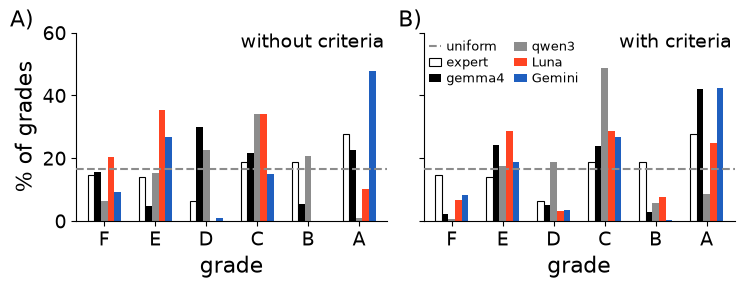

In [21]:
# 5) plot: grouped bars; A) without criteria, B) with criteria
BAR_ORDER = ["expert"] + list(LINE_STYLE)
BAR_WIDTH = 0.13
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, sharey=True)
for i, (ax, crit, note) in enumerate(zip(axes, (False, True), ("without criteria", "with criteria"))):
    for j, rater in enumerate(BAR_ORDER):
        if rater == "expert":
            row = distributions[distributions.rater == "expert"].iloc[0]
            style = dict(color="white", edgecolor=BLACK, linewidth=0.8, label="expert")
        else:
            row = distributions[(distributions.rater == rater) & (distributions.criteria == crit)].iloc[0]
            style = dict(color=LINE_STYLE[rater][0], edgecolor="none", label=LEGEND_NAME[rater])
        x = np.arange(6) + (j - (len(BAR_ORDER) - 1) / 2) * BAR_WIDTH
        ax.bar(x, [100 * row[g] for g in GRADES], width=BAR_WIDTH, zorder=2, **style)
    ax.axhline(100 / 6, color=GRAY, linestyle="--", linewidth=1.5, label="uniform", zorder=3)
    ax.set_xticks(range(6), GRADES, fontsize=TICK)
    ax.set_xlabel("grade", fontsize=LABEL)
    ax.set_xlim(-0.55, 5.55)
    ax.set_ylim(0, 60)
    if i == 0:
        ax.set_ylabel("% of grades", fontsize=LABEL)
        ax.set_yticks([0, 20, 40, 60], ["0", "20", "40", "60"], fontsize=TICK)
    else:
        ax.tick_params(axis="y", labelsize=0)
    ax.text(5.5, 60, note, fontsize=TICK, ha="right", va="top")
    ax.text(-1.85 if i == 0 else -1.05, 62, "AB"[i] + ")", fontsize=LABEL)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[1].legend(loc="upper left", bbox_to_anchor=(0.0, 0.99), fontsize=9, frameon=False, ncol=2,
               handlelength=1.0, columnspacing=0.8, labelspacing=0.15, handletextpad=0.4, borderaxespad=0.0)
save_figure(fig, "Distribution_grades_expertAndModels")
plt.show()

saved paper/figures/Distribution_grades_byRater.pdf


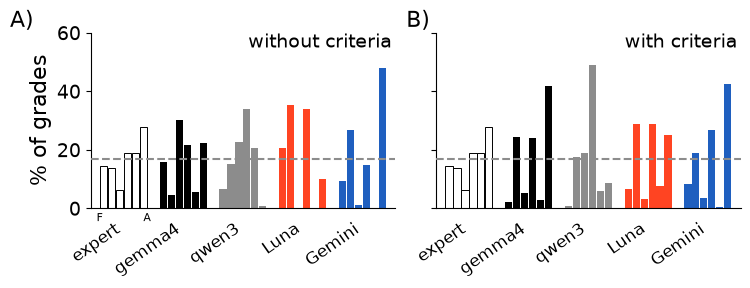

saved paper/figures/Distribution_grades_byRater_twoRows.pdf


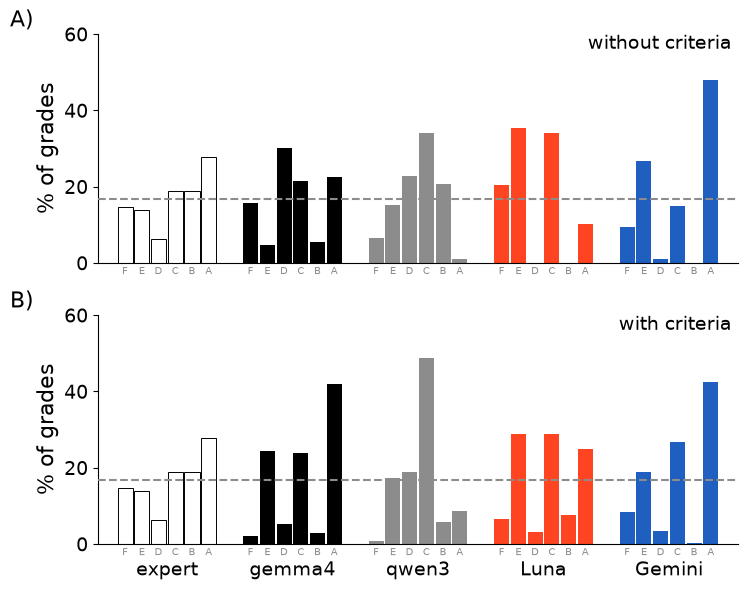

In [22]:
# 5b) alternative: grouped by rater, one small F-A histogram per rater
RATER_LABEL = {"expert": "expert", **LEGEND_NAME}


def by_rater_panel(ax, crit, rotate):
    group_width = 0.8
    w = group_width / 6
    for j, rater in enumerate(BAR_ORDER):
        if rater == "expert":
            row = distributions[distributions.rater == "expert"].iloc[0]
            style = dict(color="white", edgecolor=BLACK, linewidth=0.7)
        else:
            row = distributions[(distributions.rater == rater) & (distributions.criteria == crit)].iloc[0]
            style = dict(color=LINE_STYLE[rater][0], edgecolor="none")
        x = j + (np.arange(6) - 2.5) * w
        ax.bar(x, [100 * row[g] for g in GRADES], width=w * 0.9, zorder=2, **style)
    ax.axhline(100 / 6, color=GRAY, linestyle="--", linewidth=1.5, zorder=3)
    ax.set_xticks(range(len(BAR_ORDER)), [RATER_LABEL[r] for r in BAR_ORDER], fontsize=TICK - 2 if rotate else TICK,
                  rotation=35 if rotate else 0, ha="right" if rotate else "center")
    ax.tick_params(axis="x", length=0)
    ax.set_xlim(-0.55, len(BAR_ORDER) - 0.45)
    ax.set_ylim(0, 60)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


# variant 1: one row, A) without, B) with criteria
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, sharey=True)
for i, (ax, crit, note) in enumerate(zip(axes, (False, True), ("without criteria", "with criteria"))):
    by_rater_panel(ax, crit, rotate=True)
    if i == 0:
        ax.set_ylabel("% of grades", fontsize=LABEL)
        ax.set_yticks([0, 20, 40, 60], ["0", "20", "40", "60"], fontsize=TICK)
    else:
        ax.tick_params(axis="y", labelsize=0)
    ax.text(len(BAR_ORDER) - 0.5, 60, note, fontsize=TICK, ha="right", va="top")
    ax.text(-1.9 if i == 0 else -1.05, 62, "AB"[i] + ")", fontsize=LABEL)
axes[0].text(-0.4, -1.5, "F", fontsize=8, ha="center", va="top")        # orientation of the bars in a group
axes[0].text(0.4, -1.5, "A", fontsize=8, ha="center", va="top")
for ax in axes:
    ax.tick_params(axis="x", pad=9)          # rater names below the F / A orientation marks
save_figure(fig, "Distribution_grades_byRater")
plt.show()

# variant 2: two rows (3 in each), A) without, B) with criteria
fig, axes = plt.subplots(2, 1, figsize=(7.5, 6.0), sharex=True)
for i, (ax, crit, note) in enumerate(zip(axes, (False, True), ("without criteria", "with criteria"))):
    by_rater_panel(ax, crit, rotate=False)
    ax.set_ylabel("% of grades", fontsize=LABEL)
    ax.set_yticks([0, 20, 40, 60], ["0", "20", "40", "60"], fontsize=TICK)
    ax.text(len(BAR_ORDER) - 0.5, 60, note, fontsize=TICK, ha="right", va="top")
    ax.text(-1.25, 62, "AB"[i] + ")", fontsize=LABEL)
    for k in range(6):                                                    # grade letters under each bar
        for j in range(len(BAR_ORDER)):
            ax.text(j + (k - 2.5) * 0.8 / 6, -1.0, GRADES[k], fontsize=7, ha="center", va="top", color=GRAY)
axes[0].tick_params(axis="x", labelsize=0)
axes[1].tick_params(axis="x", pad=12)   # rater names below the grade letters
save_figure(fig, "Distribution_grades_byRater_twoRows")
plt.show()

**6) What the figure shows.**

- **Expert:** widest use of the scale (SD 1.80, F + A = 42 %), most A's (28 %), few D's (6 %).
- **With criteria (B), all models form a comb on E / C / A:** the intermediate grades D and B are almost
  never given (D 3–9 %, B 0–8 %, except qwen3's D 19 %). The task criteria describe exactly the levels
  E, C and A, and the models snap to them; the rule for D and B ("mostly meets the next level") is ignored.
- **qwen3 compresses toward C** (49 % C with criteria, SD 1.1–1.2, F + A only 7–10 %).
- **Without criteria (A), each model has its own pattern:** Gemini gives 48 % A and almost no D or B;
  Luna piles up at E and C and gives almost no D, B or A; gemma4 prefers D and A.
- For Swedish grading this means the six-step scale effectively shrinks to three or four grades, in
  different ways per model.

## 5. Context effects, raw view (SI): grade alone vs. grade in group

**Idea.** Before summarising the context effects in one number, look at them directly. For every model,
workflow (batch = whole group in one prompt, chat = one student per turn in the same conversation) and class
size: x = the text's grade when graded alone (mean over runs, same model and prompt format), y = its grade
in the group. One point per grading in a random group; pooled over all 12 assignments. Dashed diagonal =
no change; black line = mean grade in group per (rounded) grade alone.

Sources: local models `batch_main_*` (batch; reference = single texts in batch format) and `seq_main_*`
(chat; reference = one-turn conversations in the same Gem-like format); commercial models `or_ormain_*`
(batch, groups of 20 only).

In [23]:
# 2) compute: one row per grading in a random class, with the text's mean grade alone
CONTEXT_SOURCES = [  # (label, workflow, file)
    ("gemma4", "batch", "batch_main_gemma4-26b.jsonl"),
    ("gemma4", "chat", "seq_main_gemma4-26b.jsonl"),
    ("qwen3", "batch", "batch_main_qwen3-30b-a3b.jsonl"),
    ("qwen3", "chat", "seq_main_qwen3-30b-a3b.jsonl"),
    ("Luna", "batch", "or_ormain_openai-gpt-6-luna.jsonl"),
    ("Gemini", "batch", "or_ormain_google-gemini-3.1-flash-lite.jsonl"),
]


def graded_students(rec):
    """(text_id, grade) for every graded student of a batch call or chat conversation."""
    if "turns" in rec:
        return [(t["text_id"], t["grade"]) for t in rec["turns"] if t.get("grade") in NUM]
    if rec.get("error") is not None:
        return []
    if rec["batch_size"] == 1:
        g = single_grade(rec)
        return [(rec["students"][0]["text_id"], g)] if g else []
    return [(s["text_id"], s["grade"]) for s in rec["students"] if s.get("grade") in NUM]


ctx_rows = []
for label, workflow, fname in CONTEXT_SOURCES:
    recs = [json.loads(l) for l in open(RESULTS / fname, encoding="utf-8")]
    alone = defaultdict(list)
    for r in recs:
        if r["design"] == "single_code":
            for tid, g in graded_students(r):
                alone[(r["criteria"], tid)].append(NUM[g])
    for r in recs:
        m = re.fullmatch(r"random(\d+)", r["design"])
        if not m:
            continue
        for tid, g in graded_students(r):
            ref = alone.get((r["criteria"], tid))
            if ref:
                ctx_rows.append({"model": label, "workflow": workflow, "criteria": r["criteria"], "size": int(m.group(1)),
                                 "text_id": tid, "intended": INTENDED[tid], "alone": np.mean(ref),
                                 "alone_runs": len(ref), "in_class": NUM[g]})
context = pd.DataFrame(ctx_rows)
context.groupby(["model", "workflow", "criteria", "size"]).size().unstack("size")

size                          5       10      20      30
model  workflow criteria                                
Gemini batch    False        NaN     NaN  2160.0     NaN
                True         NaN     NaN  2160.0     NaN
Luna   batch    False        NaN     NaN  2160.0     NaN
                True         NaN     NaN  2160.0     NaN
gemma4 batch    False     2158.0  2159.0  2159.0  2157.0
                True      2157.0  2157.0  2160.0  2156.0
       chat     False     2159.0  2160.0  2159.0  2160.0
                True      2160.0  2159.0  2160.0  2160.0
qwen3  batch    False     2160.0  2160.0  2160.0  2160.0
                True      2160.0  2160.0  2160.0  2160.0
       chat     False     2160.0  2160.0  2159.0  2159.0
                True      2160.0  2160.0  2160.0  2160.0

In [24]:
# 3) save
context.to_pickle(DATA / "context_alone_vs_class.pkl")

In [25]:
# 4) load
context = pd.read_pickle(DATA / "context_alone_vs_class.pkl")

saved paper/figures/Scatter_aloneVsGroup_allModels_withoutCriteria.pdf


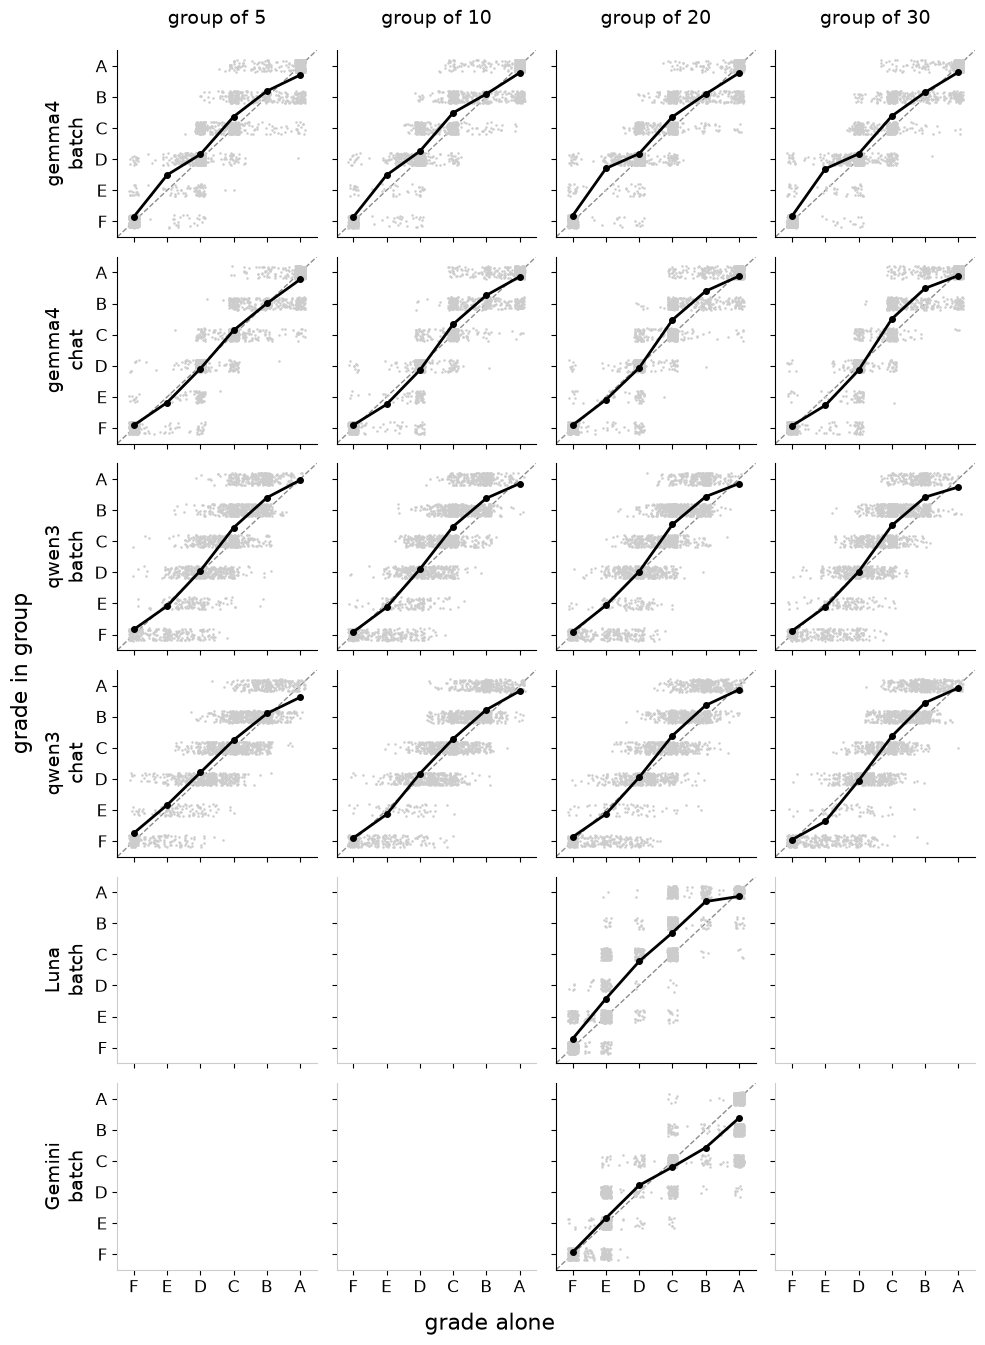

saved paper/figures/Scatter_aloneVsGroup_allModels_withCriteria.pdf


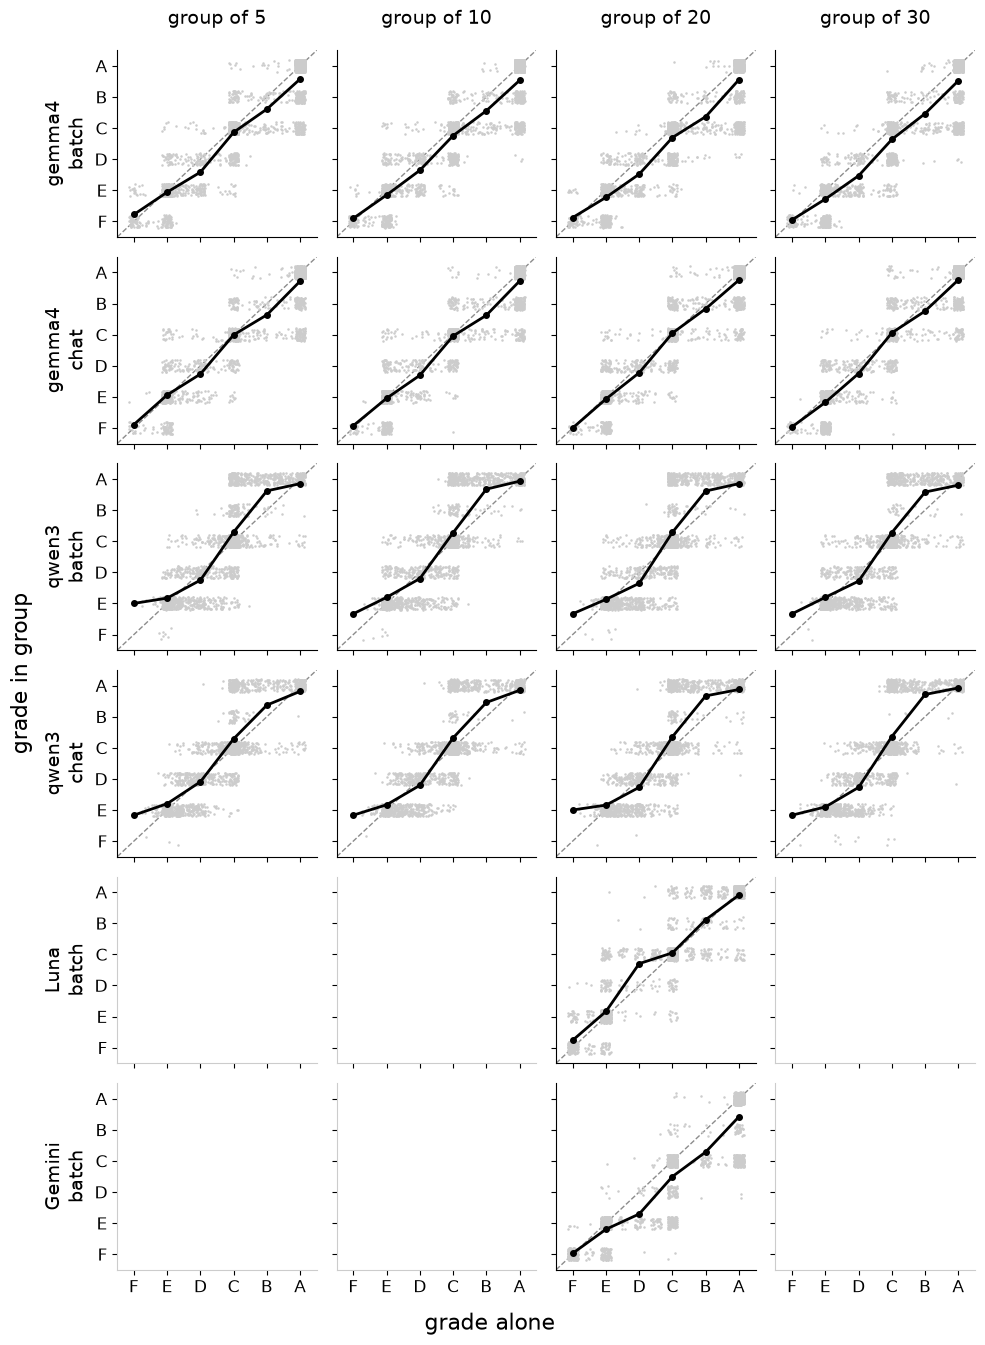

In [26]:
# 5) plot: SI figures, rows = model x workflow, columns = class size; one figure per criteria condition
ROWS = [(m, w) for m, w, _ in CONTEXT_SOURCES]
SIZES_ALL = [5, 10, 20, 30]


def plot_context_raw(crit):
    fig, axes = plt.subplots(len(ROWS), len(SIZES_ALL), figsize=(10.0, 13.5), sharex=True, sharey=True)
    for r, (model, workflow) in enumerate(ROWS):
        for c, size in enumerate(SIZES_ALL):
            ax = axes[r, c]
            d = context[(context.model == model) & (context.workflow == workflow) &
                        (context.criteria == crit) & (context["size"] == size)]
            for side in ("top", "right"):
                ax.spines[side].set_visible(False)
            if d.empty:
                ax.set_facecolor("white")
                for side in ("left", "bottom"):
                    ax.spines[side].set_color(LIGHT)
            else:
                ax.plot([-0.5, 5.5], [-0.5, 5.5], "--", color=GRAY, linewidth=1.0, zorder=1)
                ax.plot(jitter(d.alone, 0.15, seed=r * 10 + c), jitter(d.in_class, 0.2, seed=r * 10 + c + 5),
                        ".", color=LIGHT, markersize=1.6, zorder=2)
                mean = d.groupby(d.alone.round()).in_class.mean()
                ax.plot(mean.index, mean.values, "-o", color=BLACK, linewidth=2.0, markersize=4, zorder=3)
            ax.set_xlim(-0.5, 5.5)
            ax.set_ylim(-0.5, 5.5)
            ax.set_xticks(range(6), GRADES, fontsize=TICK - 2)
            ax.set_yticks(range(6), GRADES, fontsize=TICK - 2)
            if c == 0:
                ax.set_ylabel(f"{model}\n{workflow}", fontsize=TICK)
            if r == 0:
                ax.text(2.5, 6.2, f"group of {size}", fontsize=TICK, ha="center", va="bottom")
    fig.supxlabel("grade alone", fontsize=LABEL)
    fig.supylabel("grade in group", fontsize=LABEL)
    save_figure(fig, f"Scatter_aloneVsGroup_allModels_{'withCriteria' if crit else 'withoutCriteria'}")
    plt.show()


plot_context_raw(False)
plot_context_raw(True)

**6) What the figures show.**

- **Every panel scatters vertically off the diagonal:** the same text often gets a grade one step (and
  sometimes two) away from its grade alone as soon as it sits in a group. This holds for every model,
  both workflows and every group size.
- **The panels of one row look alike from 5 to 30 students:** the effect is present at the smallest group.
- **Systematic departures of the mean line (with criteria):** gemma4 in batch grades C–B texts lower than
  alone; qwen3 lifts texts from C upward (many B/C texts become A) and lifts F to E; Gemini grades its
  top texts lower. Without criteria, Luna is clearly more lenient in group than alone.
- **Caution:** x is the model's own grade alone (mean of 2–3 runs). Grouping by a noisy measurement
  produces regression toward the middle at the edges (texts graded F alone can only move up, A only down).
  For the summary figure in the main text, texts are therefore grouped by their intended grade, which is
  independent of the model's noise.

## 6. Context effects: absolute deviation from the grade alone, by group size

**Idea.** Grades move up for some texts and down for others (section 5), so a signed mean would cancel.
We therefore use the **absolute deviation** |Δ grade| (grade steps) of a grade from the same model's grade
for the same text graded alone, as a function of group size.

**Fair noise baseline.** Each text was graded alone k times (k = 3 local, 2 commercial). Both quantities
are measured against the mean of k − 1 alone runs:
- group size 1 (noise): one alone run vs. the mean of the other k − 1 alone runs;
- group sizes 5–30: the grade in the group vs. the mean of k − 1 alone runs (averaged over the k choices).

So noise and group deviations have exactly the same reference structure.

**Test.** Per model × workflow × criteria × group size: paired one-sided Wilcoxon signed-rank test over
texts (per-text mean |Δ| in the group vs. per-text noise |Δ|), Holm correction over all tests.
Figure without significance marks; the full test table goes to the SI (LaTeX, `paper/tables/`)
and the range of p-values into the caption.

In [27]:
# 2) compute: per-text mean absolute deviation, noise (size 1) and in classes
from scipy import stats


def loo_mean(runs, i):
    return np.mean(runs[:i] + runs[i + 1:])


dev_rows = []
for label, workflow, fname in CONTEXT_SOURCES:
    recs = [json.loads(l) for l in open(RESULTS / fname, encoding="utf-8")]
    alone = defaultdict(list)
    for r in recs:
        if r["design"] == "single_code":
            for tid, g in graded_students(r):
                alone[(r["criteria"], tid)].append(NUM[g])
    for (crit, tid), runs in alone.items():
        if len(runs) >= 2:
            dev_rows.append({"model": label, "workflow": workflow, "criteria": crit, "size": 1, "text_id": tid,
                             "absdev": np.mean([abs(runs[i] - loo_mean(runs, i)) for i in range(len(runs))])})
    in_class = defaultdict(list)
    for r in recs:
        m = re.fullmatch(r"random(\d+)", r["design"])
        if not m:
            continue
        for tid, g in graded_students(r):
            runs = alone.get((r["criteria"], tid), [])
            if len(runs) >= 2:
                in_class[(r["criteria"], int(m.group(1)), tid)].append(
                    np.mean([abs(NUM[g] - loo_mean(runs, i)) for i in range(len(runs))]))
    for (crit, size, tid), v in in_class.items():
        dev_rows.append({"model": label, "workflow": workflow, "criteria": crit, "size": size, "text_id": tid,
                         "absdev": np.mean(v)})
deviation = pd.DataFrame(dev_rows)

# paired tests: each class size vs. noise (size 1), per model x workflow x criteria
test_rows = []
for (model, workflow, crit), grp in deviation.groupby(["model", "workflow", "criteria"]):
    noise = grp[grp["size"] == 1].set_index("text_id").absdev
    for size in sorted(s for s in grp["size"].unique() if s > 1):
        cls = grp[grp["size"] == size].set_index("text_id").absdev
        both = pd.concat([cls, noise], axis=1, keys=["cls", "noise"]).dropna()
        diff = both.cls - both.noise
        w = stats.wilcoxon(diff, alternative="greater")
        test_rows.append({"model": model, "workflow": workflow, "criteria": crit, "size": size, "texts": len(both),
                          "noise": both.noise.mean(), "class": both.cls.mean(), "excess": diff.mean(), "p": w.pvalue})
tests = pd.DataFrame(test_rows)
order = np.argsort(tests.p.values)          # Holm correction over all tests
m = len(tests)
holm = np.empty(m)
running = 0.0
for rank, idx in enumerate(order):
    running = max(running, min(1.0, (m - rank) * tests.p.values[idx]))
    holm[idx] = running
tests["p_holm"] = holm
tests["significant"] = tests.p_holm < 0.05

In [28]:
# 3) save
deviation.to_pickle(DATA / "absdev_by_size.pkl")
tests.to_pickle(DATA / "absdev_tests.pkl")

In [29]:
# 4) load
deviation = pd.read_pickle(DATA / "absdev_by_size.pkl")
tests = pd.read_pickle(DATA / "absdev_tests.pkl")
pd.set_option("display.float_format", lambda v: f"{v:.3g}")
tests.sort_values(["criteria", "model", "workflow", "size"])

,model,workflow,criteria,size,texts,noise,class,excess,p,p_holm,significant
0,Gemini,batch,False,20,720,0.132,0.547,0.416,1.06e-47,2.23e-46,True
2,Luna,batch,False,20,720,0.214,0.628,0.414,1.57e-34,1.89e-33,True
4,gemma4,batch,False,5,720,0.13,0.401,0.271,1.31e-59,3.93e-58,True
5,gemma4,batch,False,10,720,0.13,0.396,0.267,3.13e-54,8.44e-53,True
6,gemma4,batch,False,20,720,0.13,0.379,0.249,9.08e-50,2.36e-48,True
7,gemma4,batch,False,30,720,0.13,0.378,0.248,1.39e-48,3.19e-47,True
12,gemma4,chat,False,5,720,0.0949,0.285,0.19,6.32e-46,1.2e-44,True
13,gemma4,chat,False,10,720,0.0949,0.31,0.215,5e-46,9.99e-45,True
14,gemma4,chat,False,20,720,0.0949,0.328,0.233,6.76e-45,1.22e-43,True
15,gemma4,chat,False,30,720,0.0949,0.333,0.238,1.09e-42,1.74e-41,True


saved paper/figures/Deviation_absVsGroupSize_allModels.pdf


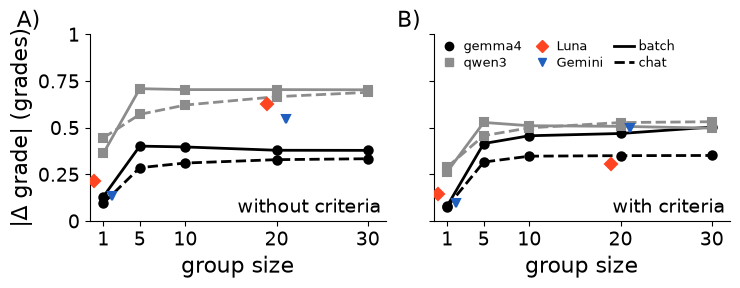

In [30]:
# 5) plot: A) without criteria, B) with criteria; solid = batch, dashed = chat; commercial = points at 20
MODEL_COLOR = {"gemma4": BLACK, "qwen3": "0.55", "Luna": RED, "Gemini": "#1f5fbf"}
MODEL_MARKER = {"gemma4": "o", "qwen3": "s", "Luna": "D", "Gemini": "v"}


def stars(p):
    """Significance stars (Holm-corrected p): * < 0.01, ** < 0.001, *** < 0.0001."""
    return "***" if p < 1e-4 else "**" if p < 1e-3 else "*" if p < 1e-2 else ""
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, sharey=True)
for i, (ax, crit, note) in enumerate(zip(axes, (False, True), ("without criteria", "with criteria"))):
    for (model, workflow), grp in deviation[deviation.criteria == crit].groupby(["model", "workflow"]):
        means = grp.groupby("size").absdev.mean()
        tsel = tests[(tests.model == model) & (tests.workflow == workflow) & (tests.criteria == crit)].set_index("size")
        sig, p_holm = tsel.significant, tsel.p_holm
        color, marker = MODEL_COLOR[model], MODEL_MARKER[model]
        commercial = model in ("Luna", "Gemini")
        if not commercial:
            ax.plot(means.index, means.values, "-" if workflow == "batch" else "--", color=color, linewidth=2.0, zorder=2)
        offset = {"Luna": -1.0, "Gemini": 1.0}.get(model, 0.0)   # keep commercial points visible
        for size, val in means.items():
            filled = size == 1 or bool(sig.get(size, False))
            ax.plot(size + offset, val, marker, color=color, markersize=6, zorder=5 if commercial else 3,
                    markerfacecolor=color if filled else "white", markeredgewidth=1.5)
    ax.set_xticks([1, 5, 10, 20, 30], ["1", "5", "10", "20", "30"], fontsize=TICK)
    ax.set_xlim(-0.5, 32)
    ax.set_ylim(0, 1.0)
    ax.set_xlabel("group size", fontsize=LABEL)
    if i == 0:
        ax.set_ylabel("|Δ grade| (grades)", fontsize=LABEL)
        ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0], ["0", "0.25", "0.5", "0.75", "1"], fontsize=TICK)
    else:
        ax.tick_params(axis="y", labelsize=0)
    ax.text(31.5, 0.02, note, fontsize=TICK, ha="right", va="bottom")
    ax.text(-8.5 if i == 0 else -4.5, 1.04, "AB"[i] + ")", fontsize=LABEL)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
from matplotlib.lines import Line2D
handles = [Line2D([], [], color=MODEL_COLOR[m], marker=MODEL_MARKER[m], linestyle="none", markersize=6, label=m)
           for m in MODEL_COLOR]
handles += [Line2D([], [], color=BLACK, linestyle="-", linewidth=2, label="batch"),
            Line2D([], [], color=BLACK, linestyle="--", linewidth=2, label="chat")]
axes[1].legend(handles=handles, loc="upper left", fontsize=9, frameon=False, ncol=3, handlelength=1.6,
               columnspacing=0.8, labelspacing=0.2, handletextpad=0.4, borderaxespad=0.0)
save_figure(fig, "Deviation_absVsGroupSize_allModels")
plt.show()

In [31]:
# 5b) SI table (LaTeX) and the p-value range for the figure caption
TABLES = ROOT / "paper" / "tables"
TABLES.mkdir(exist_ok=True)


def sci(p):
    mant, exp = f"{p:.1e}".split("e")
    return f"${mant}\\times10^{{{int(exp)}}}$"


t = tests.sort_values(["criteria", "model", "workflow", "size"])
lines = [r"\begin{tabular}{llcrccccc}", r"\toprule",
         r"Criteria & Model & Workflow & Group size & Texts & $|\Delta|$ alone & $|\Delta|$ in group & Excess & $p_\mathrm{Holm}$ \\",
         r"\midrule"]
prev = None
for _, r in t.iterrows():
    if prev is not None and r.criteria != prev:
        lines.append(r"\midrule")
    prev = r.criteria
    lines.append(f"{'with' if r.criteria else 'without'} & {r.model} & {r.workflow} & {r['size']} & {r.texts} & "
                 f"{r.noise:.2f} & {r['class']:.2f} & {r.excess:.2f} & {sci(r.p_holm)} \\\\")
lines += [r"\bottomrule", r"\end{tabular}"]
(TABLES / "Table_absDeviationTests.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("saved", TABLES / "Table_absDeviationTests.tex")
print(f"caption: all {len(tests)} group conditions deviate more than the run-to-run noise "
      f"(paired one-sided Wilcoxon signed-rank tests over 720 texts, Holm-corrected, "
      f"p = {tests.p_holm.max():.1e} to {tests.p_holm.min():.1e})")

saved paper/tables/Table_absDeviationTests.tex
caption: all 36 group conditions deviate more than the run-to-run noise (paired one-sided Wilcoxon signed-rank tests over 720 texts, Holm-corrected, p = 1.9e-15 to 2.4e-64)


**6) What the figure shows.**

- **Noise level (group size 1):** gemma4 0.08–0.13 grade steps, Gemini 0.09–0.13, Luna 0.15–0.21,
  qwen3 0.26–0.45.
- **Every group condition deviates more than the model's own noise:** all 36 paired tests are significant
  after Holm correction (p_Holm = 1.9·10⁻¹⁵ to 2.4·10⁻⁶⁴; 720 texts each).
- **Batch (solid):** the deviation jumps to its full size already at 5 students and stays there
  (gemma4 with criteria still rises slightly, 0.42 → 0.50).
- **Chat (dashed):** somewhat smaller than batch, and it grows with group size as the history gets
  longer (e.g. qwen3 without criteria 0.57 → 0.69).
- **Commercial models at group size 20:** Gemini moves from 0.09–0.13 alone to 0.50–0.55 in a group
  (four to five times its noise), similar to the local models; Luna 0.31 with and 0.63 without criteria.
- Excess over noise: 0.13–0.42 grade steps, i.e. on average a third of a grade step per student, in
  either direction.

## 7. Contrast effect: the same texts among weak, middle and strong classmates

**Idea.** Groups of 20 composed with discretised normal grade distributions (weak: mean between E and D;
middle: between D and C; strong: between C and B). Texts with intended grade D or C occur in all three
profiles. For these texts: signed change of the grade in the group vs. the same model's mean grade for
the text alone (grade steps). Here the sign is the message (up among weak, down among strong classmates),
so a signed mean is appropriate. Texts are selected by intended grade, which is independent of the
model's noise (no regression artefact).

Batch for all four models, chat for gemma4 and qwen3. Whiskers: 95 % bootstrap CI over texts.

**Test.** Per model × workflow × criteria: paired one-sided Wilcoxon signed-rank test over texts that occur
in both the weak and the strong profile (per-text mean change weak > strong), Holm correction over all
tests. Effect size: gap = mean change weak − mean change strong. Figure without significance marks; table
to the SI, p-value range into the caption.

In [32]:
# 2) compute: per-text mean change (class - alone) of D/C texts in each profile
PROFILES = ["profile_weak", "profile_middle", "profile_strong"]
con_rows = []
for label, workflow, fname in CONTEXT_SOURCES:
    recs = [json.loads(l) for l in open(RESULTS / fname, encoding="utf-8")]
    alone = defaultdict(list)
    for r in recs:
        if r["design"] == "single_code":
            for tid, g in graded_students(r):
                alone[(r["criteria"], tid)].append(NUM[g])
    changes = defaultdict(list)
    for r in recs:
        if r["design"] in PROFILES:
            for tid, g in graded_students(r):
                if KEY[tid]["intended_grade"] in "DC" and alone.get((r["criteria"], tid)):
                    changes[(r["criteria"], r["design"], tid)].append(NUM[g] - np.mean(alone[(r["criteria"], tid)]))
    for (crit, profile, tid), v in changes.items():
        con_rows.append({"model": label, "workflow": workflow, "criteria": crit,
                         "profile": profile.split("_")[1], "text_id": tid, "change": np.mean(v), "n": len(v)})
contrast = pd.DataFrame(con_rows)


def boot_ci(values, n_boot=2000, seed=11):
    rng = np.random.default_rng(seed)
    v = np.asarray(values)
    means = rng.choice(v, (n_boot, len(v)), replace=True).mean(1)
    return np.percentile(means, [2.5, 97.5])


summary_rows, con_tests = [], []
for (model, workflow, crit), grp in contrast.groupby(["model", "workflow", "criteria"]):
    for prof in ("weak", "middle", "strong"):
        v = grp[grp.profile == prof].change.values
        lo, hi = boot_ci(v)
        summary_rows.append({"model": model, "workflow": workflow, "criteria": crit, "profile": prof,
                             "mean": v.mean(), "lo": lo, "hi": hi, "texts": len(v)})
    wide = grp.pivot_table(index="text_id", columns="profile", values="change")
    both = wide[["weak", "strong"]].dropna()
    w = stats.wilcoxon(both.weak - both.strong, alternative="greater")
    con_tests.append({"model": model, "workflow": workflow, "criteria": crit, "texts": len(both),
                      "weak": both.weak.mean(), "middle": wide.middle.mean(), "strong": both.strong.mean(),
                      "gap": (both.weak - both.strong).mean(), "p": w.pvalue})
contrast_summary = pd.DataFrame(summary_rows)
contrast_tests = pd.DataFrame(con_tests)
order = np.argsort(contrast_tests.p.values)
holm, running, m = np.empty(len(order)), 0.0, len(order)
for rank, idx in enumerate(order):
    running = max(running, min(1.0, (m - rank) * contrast_tests.p.values[idx]))
    holm[idx] = running
contrast_tests["p_holm"] = holm

In [33]:
# 3) save
contrast.to_pickle(DATA / "contrast_by_text.pkl")
contrast_summary.to_pickle(DATA / "contrast_summary.pkl")
contrast_tests.to_pickle(DATA / "contrast_tests.pkl")

In [34]:
# 4) load
contrast_summary = pd.read_pickle(DATA / "contrast_summary.pkl")
contrast_tests = pd.read_pickle(DATA / "contrast_tests.pkl")
contrast_tests.sort_values(["criteria", "model", "workflow"])

,model,workflow,criteria,texts,weak,middle,strong,gap,p,p_holm
0,Gemini,batch,False,211,0.385,-0.396,-1.27,1.65,1.06e-36,1.17e-35
2,Luna,batch,False,211,1.1,0.559,-0.031,1.14,2.22e-33,1.11e-32
4,gemma4,batch,False,211,0.926,0.206,-0.308,1.23,2.02e-36,2.02e-35
6,gemma4,chat,False,211,0.635,0.161,-0.321,0.956,1.95e-34,1.36e-33
8,qwen3,batch,False,211,0.998,0.449,-0.0139,1.01,1.6e-34,1.28e-33
10,qwen3,chat,False,211,0.768,0.21,-0.177,0.945,1.3e-33,7.79e-33
1,Gemini,batch,True,211,0.364,-0.657,-1.67,2.04,7.04e-37,8.44e-36
3,Luna,batch,True,211,0.81,0.2,-0.38,1.19,2.51e-32,7.53e-32
5,gemma4,batch,True,211,0.276,-0.497,-1.17,1.45,3.04e-35,2.74e-34
7,gemma4,chat,True,211,0.357,-0.0866,-0.651,1.01,2.96e-33,1.18e-32


saved paper/figures/Contrast_changeVsClassmates_allModels.pdf


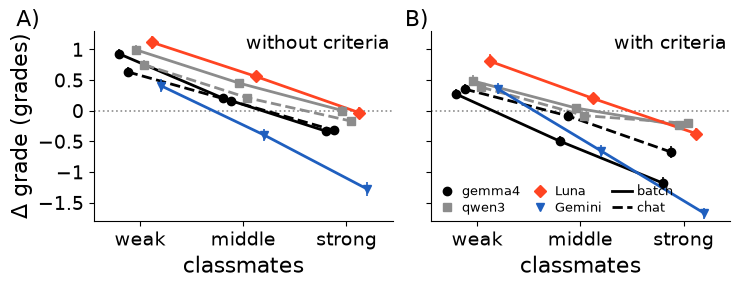

In [35]:
# 5) plot: A) without criteria, B) with criteria; x = class profile, y = signed change of D/C texts
SERIES = [("gemma4", "batch"), ("gemma4", "chat"), ("qwen3", "batch"), ("qwen3", "chat"), ("Luna", "batch"), ("Gemini", "batch")]
X_OFFSET = dict(zip(SERIES, np.linspace(-0.2, 0.2, len(SERIES))))
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, sharey=True)
for i, (ax, crit, note) in enumerate(zip(axes, (False, True), ("without criteria", "with criteria"))):
    ax.axhline(0, color=GRAY, linestyle=":", linewidth=1.2, zorder=1)
    for model, workflow in SERIES:
        d = contrast_summary[(contrast_summary.model == model) & (contrast_summary.workflow == workflow) &
                             (contrast_summary.criteria == crit)].set_index("profile").loc[["weak", "middle", "strong"]]
        x = np.arange(3) + X_OFFSET[(model, workflow)]
        color, marker = MODEL_COLOR[model], MODEL_MARKER[model]
        ax.plot(x, d["mean"], "-" if workflow == "batch" else "--", color=color, linewidth=2.0, zorder=2)
        ax.errorbar(x, d["mean"], yerr=[d["mean"] - d.lo, d.hi - d["mean"]], fmt=marker, color=color,
                    markersize=6, elinewidth=1.2, capsize=0, zorder=3)
    ax.set_xticks(range(3), ["weak", "middle", "strong"], fontsize=TICK)
    ax.set_xlim(-0.45, 2.45)
    ax.set_ylim(-1.8, 1.3)
    ax.set_xlabel("classmates", fontsize=LABEL)
    if i == 0:
        ax.set_ylabel("Δ grade (grades)", fontsize=LABEL)
        ax.set_yticks([-1.5, -1, -0.5, 0, 0.5, 1], ["−1.5", "−1", "−0.5", "0", "0.5", "1"], fontsize=TICK)
    else:
        ax.tick_params(axis="y", labelsize=0)
    ax.text(2.42, 1.25, note, fontsize=TICK, ha="right", va="top")
    ax.text(-1.2 if i == 0 else -0.7, 1.38, "AB"[i] + ")", fontsize=LABEL)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
handles = [Line2D([], [], color=MODEL_COLOR[m], marker=MODEL_MARKER[m], linestyle="none", markersize=6, label=m)
           for m in MODEL_COLOR]
handles += [Line2D([], [], color=BLACK, linestyle="-", linewidth=2, label="batch"),
            Line2D([], [], color=BLACK, linestyle="--", linewidth=2, label="chat")]
axes[1].legend(handles=handles, loc="lower left", fontsize=9, frameon=False, ncol=3, handlelength=1.6,
               columnspacing=0.8, labelspacing=0.2, handletextpad=0.4, borderaxespad=0.1)
save_figure(fig, "Contrast_changeVsClassmates_allModels")
plt.show()

In [36]:
# 5b) SI table (LaTeX) and the p-value range for the caption
t = contrast_tests.sort_values(["criteria", "model", "workflow"])
lines = [r"\begin{tabular}{llcrccccc}", r"\toprule",
         r"Criteria & Model & Workflow & Texts & Weak & Middle & Strong & Gap & $p_\mathrm{Holm}$ \\", r"\midrule"]
prev = None
for _, r in t.iterrows():
    if prev is not None and r.criteria != prev:
        lines.append(r"\midrule")
    prev = r.criteria
    lines.append(f"{'with' if r.criteria else 'without'} & {r.model} & {r.workflow} & {r.texts} & {r.weak:+.2f} & "
                 f"{r.middle:+.2f} & {r.strong:+.2f} & {r.gap:.2f} & {sci(r.p_holm)} \\\\")
lines += [r"\bottomrule", r"\end{tabular}"]
(TABLES / "Table_contrastTests.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("saved", TABLES / "Table_contrastTests.tex")
print(f"caption: gap {contrast_tests.gap.min():.2f} to {contrast_tests.gap.max():.2f} grade steps; "
      f"p_Holm = {contrast_tests.p_holm.max():.1e} to {contrast_tests.p_holm.min():.1e} ({len(contrast_tests)} tests)")

saved paper/tables/Table_contrastTests.tex
caption: gap 0.62 to 2.04 grade steps; p_Holm = 1.5e-26 to 8.4e-36 (12 tests)


**6) What the figure shows.**

- **Every model grades the same D/C texts higher among weak and lower among strong classmates**, in both
  workflows and with and without criteria: all 12 weak-vs-strong tests are significant (paired Wilcoxon over
  211 texts, Holm-corrected, p = 1.5·10⁻²⁶ to 8.4·10⁻³⁶).
- **Size of the effect (gap weak − strong):** 0.62 to 2.04 grade steps. Largest for Gemini (1.65 without,
  2.04 with criteria), then gemma4 batch (1.23 / 1.45); smallest for qwen3 with criteria (0.62–0.77).
- **Chat is weaker than batch** for gemma4 (0.96 vs. 1.23 without, 1.01 vs. 1.45 with criteria) and
  qwen3, but clearly present.
- **Criteria do not remove the effect;** for gemma4 batch and Gemini it is larger with criteria.
- **Overall level differs by model** (Luna and qwen3 above zero in most profiles, Gemini and gemma4 with
  criteria below), but the slope from weak to strong is the same in all: a relative, class-referenced
  judgement inside a criterion-referenced grading system.
- Per-text means: each text contributes one mean change per profile, so numbers differ slightly from
  earlier per-grading summaries.

## 8. Deviation from the grade alone by text level and by school year (SI)

**Idea.** Is the deviation from the grade alone (section 6) concentrated in some texts? Per text: excess
deviation = mean |Δ| in random groups (all group sizes pooled) minus the text's run-to-run noise |Δ| (group
size 1). Texts are split by intended grade into low (F, E), middle (D, C) and high (B, A), and by school year
(6–9, from the task). The intended grade is only used to split the texts, not as a reference.

**Test.** Per model × workflow × criteria: Kruskal–Wallis test across levels and across school years
(per-text excess), Holm-corrected within each family (12 tests each).

In [37]:
# 2) compute: per-text excess deviation (groups pooled minus noise), with level and school year
def holm_correct(p):
    p = np.asarray(p, dtype=float)
    out, running = np.empty(len(p)), 0.0
    for rank, idx in enumerate(np.argsort(p)):
        running = max(running, min(1.0, (len(p) - rank) * p[idx]))
        out[idx] = running
    return out


LEVEL = {"F": "low", "E": "low", "D": "middle", "C": "middle", "B": "high", "A": "high"}
noise_t = deviation[deviation["size"] == 1].set_index(["model", "workflow", "criteria", "text_id"]).absdev
group_t = (deviation[deviation["size"] > 1].groupby(["model", "workflow", "criteria", "text_id"]).absdev.mean())
excess = pd.concat([group_t, noise_t], axis=1, keys=["group", "noise"]).dropna().reset_index()
excess["excess"] = excess.group - excess.noise
excess["level"] = excess.text_id.map(lambda t: LEVEL[KEY[t]["intended_grade"]])
excess["year"] = excess.text_id.str[1].astype(int)

split_rows = []
for (model, workflow, crit), grp in excess.groupby(["model", "workflow", "criteria"]):
    row = {"model": model, "workflow": workflow, "criteria": crit, "texts": len(grp)}
    for lv in ("low", "middle", "high"):
        row[lv] = grp[grp.level == lv].excess.mean()
    for y in (6, 7, 8, 9):
        row[f"y{y}"] = grp[grp.year == y].excess.mean()
    row["p_level"] = stats.kruskal(*[grp[grp.level == lv].excess for lv in ("low", "middle", "high")]).pvalue
    row["p_year"] = stats.kruskal(*[grp[grp.year == y].excess for y in (6, 7, 8, 9)]).pvalue
    split_rows.append(row)
split_tests = pd.DataFrame(split_rows)
split_tests["p_level_holm"] = holm_correct(split_tests.p_level)
split_tests["p_year_holm"] = holm_correct(split_tests.p_year)
split_tests.round(3)

,model,workflow,criteria,texts,low,middle,high,y6,y7,y8,y9,p_level,p_year,p_level_holm,p_year_holm
0,Gemini,batch,False,720,0.258,0.67,0.318,0.433,0.36,0.338,0.531,0,0.046,0,0.475
1,Gemini,batch,True,720,0.247,0.749,0.211,0.461,0.415,0.289,0.444,0,0.083,0,0.608
2,Luna,batch,False,720,0.199,0.551,0.492,0.315,0.513,0.478,0.35,0,0.076,0,0.608
3,Luna,batch,True,720,0.132,0.249,0.101,0.147,0.164,0.163,0.168,0,0.722,0,1
4,gemma4,batch,False,720,0.126,0.377,0.273,0.287,0.264,0.245,0.239,0,0.682,0,1
5,gemma4,batch,True,720,0.336,0.609,0.193,0.393,0.385,0.342,0.398,0,0.888,0,1
6,gemma4,chat,False,720,0.2,0.291,0.167,0.28,0.223,0.183,0.191,0,0.043,0,0.475
7,gemma4,chat,True,720,0.332,0.375,0.087,0.272,0.291,0.199,0.297,0,0.036,0,0.431
8,qwen3,batch,False,720,0.254,0.316,0.459,0.332,0.364,0.349,0.327,0,0.915,0,1
9,qwen3,batch,True,720,0.114,0.197,0.428,0.277,0.259,0.214,0.235,0,0.275,0,1


In [38]:
# 3) save
excess.to_pickle(DATA / "excess_by_level_year.pkl")
split_tests.to_pickle(DATA / "excess_split_tests.pkl")

In [39]:
# 4) load
excess = pd.read_pickle(DATA / "excess_by_level_year.pkl")
split_tests = pd.read_pickle(DATA / "excess_split_tests.pkl")

saved paper/figures/Deviation_excessByLevelAndYear_allModels.pdf


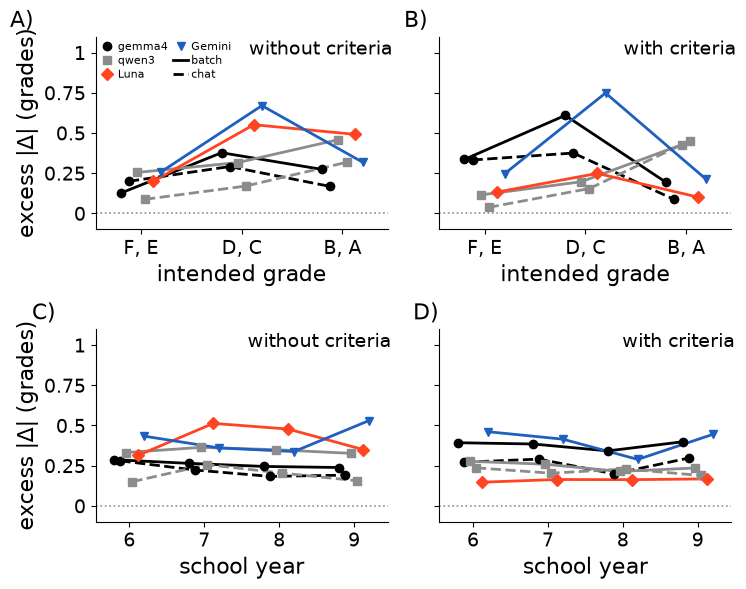

saved paper/tables/Table_excessByLevelAndYear.tex


,model,workflow,criteria,low,middle,high,p_level_holm,y6,y7,y8,y9,p_year_holm
0,Gemini,batch,False,0.258,0.67,0.318,0,0.433,0.36,0.338,0.531,0.475
1,Gemini,batch,True,0.247,0.749,0.211,0,0.461,0.415,0.289,0.444,0.608
2,Luna,batch,False,0.199,0.551,0.492,0,0.315,0.513,0.478,0.35,0.608
3,Luna,batch,True,0.132,0.249,0.101,0,0.147,0.164,0.163,0.168,1
4,gemma4,batch,False,0.126,0.377,0.273,0,0.287,0.264,0.245,0.239,1
5,gemma4,batch,True,0.336,0.609,0.193,0,0.393,0.385,0.342,0.398,1
6,gemma4,chat,False,0.2,0.291,0.167,0,0.28,0.223,0.183,0.191,0.475
7,gemma4,chat,True,0.332,0.375,0.087,0,0.272,0.291,0.199,0.297,0.431
8,qwen3,batch,False,0.254,0.316,0.459,0,0.332,0.364,0.349,0.327,1
9,qwen3,batch,True,0.114,0.197,0.428,0,0.277,0.259,0.214,0.235,1


In [40]:
# 5) plot: rows = text level / school year, columns = without / with criteria; SI table with the tests
SERIES = [("gemma4", "batch"), ("gemma4", "chat"), ("qwen3", "batch"), ("qwen3", "chat"), ("Luna", "batch"),
          ("Gemini", "batch")]
X_OFFSET = dict(zip(SERIES, np.linspace(-0.2, 0.2, len(SERIES))))
fig, axes = plt.subplots(2, 2, figsize=(7.5, 6.0), sharey=True)
for r, (col, cats, ticks, xlabel) in enumerate([("level", ["low", "middle", "high"], ["F, E", "D, C", "B, A"], "intended grade"),
                                                ("year", [6, 7, 8, 9], ["6", "7", "8", "9"], "school year")]):
    for c, (crit, note) in enumerate(zip((False, True), ("without criteria", "with criteria"))):
        ax = axes[r, c]
        ax.axhline(0, color=GRAY, linestyle=":", linewidth=1.2, zorder=1)
        for model, workflow in SERIES:
            d = excess[(excess.model == model) & (excess.workflow == workflow) & (excess.criteria == crit)]
            m = d.groupby(col).excess.mean().reindex(cats)
            x = np.arange(len(cats)) + X_OFFSET[(model, workflow)]
            ax.plot(x, m.values, "-" if workflow == "batch" else "--", color=MODEL_COLOR[model], linewidth=2.0, zorder=2)
            ax.plot(x, m.values, MODEL_MARKER[model], color=MODEL_COLOR[model], markersize=6, zorder=3)
        ax.set_xticks(range(len(cats)), ticks, fontsize=TICK)
        ax.set_xlim(-0.45, len(cats) - 0.55)
        ax.set_ylim(-0.1, 1.1)
        ax.set_xlabel(xlabel, fontsize=LABEL)
        if c == 0:
            ax.set_ylabel("excess |Δ| (grades)", fontsize=LABEL)
            ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0], ["0", "0.25", "0.5", "0.75", "1"], fontsize=TICK)
        else:
            ax.tick_params(axis="y", labelsize=0)
        ax.text(len(cats) - 0.5, 1.08, note, fontsize=TICK, ha="right", va="top")
        ax.text(-1.3 if c == 0 else -0.8, 1.16, "ABCD"[2 * r + c] + ")", fontsize=LABEL)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
handles = [Line2D([], [], color=MODEL_COLOR[m], marker=MODEL_MARKER[m], linestyle="none", markersize=6, label=m)
           for m in MODEL_COLOR]
handles += [Line2D([], [], color=BLACK, linestyle="-", linewidth=2, label="batch"),
            Line2D([], [], color=BLACK, linestyle="--", linewidth=2, label="chat")]
axes[0, 0].legend(handles=handles, loc="upper left", fontsize=8, frameon=False, ncol=2, handlelength=1.3,
                  columnspacing=0.5, labelspacing=0.2, handletextpad=0.3, borderaxespad=0.0)
save_figure(fig, "Deviation_excessByLevelAndYear_allModels")
plt.show()

def pfmt(p):
    return sci(p) if p < 0.001 else f"{p:.2f}"


t = split_tests.sort_values(["criteria", "model", "workflow"])
lines = [r"\begin{tabular}{llcccccccccc}", r"\toprule",
         r" & & & \multicolumn{4}{c}{Intended grade} & \multicolumn{5}{c}{School year} \\",
         r"\cmidrule(lr){4-7}\cmidrule(lr){8-12}",
         r"Criteria & Model & Workflow & F, E & D, C & B, A & $p_\mathrm{Holm}$ & 6 & 7 & 8 & 9 & $p_\mathrm{Holm}$ \\",
         r"\midrule"]
prev = None
for _, r in t.iterrows():
    if prev is not None and r.criteria != prev:
        lines.append(r"\midrule")
    prev = r.criteria
    lines.append(f"{'with' if r.criteria else 'without'} & {r.model} & {r.workflow} & {r.low:.2f} & {r.middle:.2f} & "
                 f"{r.high:.2f} & {pfmt(r.p_level_holm)} & {r.y6:.2f} & {r.y7:.2f} & {r.y8:.2f} & {r.y9:.2f} & "
                 f"{pfmt(r.p_year_holm)} \\\\")
lines += [r"\bottomrule", r"\end{tabular}"]
(TABLES / "Table_excessByLevelAndYear.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("saved", TABLES / "Table_excessByLevelAndYear.tex")
split_tests[["model", "workflow", "criteria", "low", "middle", "high", "p_level_holm", "y6", "y7", "y8", "y9",
             "p_year_holm"]].round(3)

**6) What the figure shows.**

- **Text level matters (all 12 Kruskal–Wallis tests p_Holm ≤ 2.6·10⁻⁴):** for gemma4, Luna and Gemini in
  the batch workflow the excess deviation is largest for middle texts (D, C: 0.38–0.75 grades), which can
  move in both directions. qwen3 deviates most for high texts (B, A: 0.32–0.46), where it compresses the scale.
- **School year does not matter (all p_Holm ≥ 0.43):** the excess is similar in years 6 to 9 for every
  model, workflow and criteria condition. The effect is not tied to the difficulty of the tasks.

## 9. Feedback length by group size and workflow (SI)

**Idea.** Every grading contains short feedback to the student (`aterkoppling`). Does a student get less
feedback when graded together with others? Mean length in characters per model × workflow × criteria ×
group size; group size 1 = graded alone (in the prompt format of the workflow).

In [41]:
# 2) compute: feedback length (characters) of every graded student, alone and in random groups
def graded_feedback(rec):
    """(position, text_id, grade, feedback) for every graded student of a call or conversation."""
    if "turns" in rec:
        return [(t["position"], t["text_id"], t["grade"], t.get("aterkoppling") or "") for t in rec["turns"]
                if t.get("grade") in NUM]
    if rec.get("error") is not None:
        return []
    out = []
    for s in rec["students"]:
        g = s.get("grade") if s.get("grade") in NUM else (single_grade(rec) if rec["batch_size"] == 1 else None)
        if g in NUM:
            out.append((s["position"], s["text_id"], g, s.get("aterkoppling") or ""))
    return out


fb_rows = []
for label, workflow, fname in CONTEXT_SOURCES:
    for line in open(RESULTS / fname, encoding="utf-8"):
        r = json.loads(line)
        m = re.fullmatch(r"random(\d+)", r["design"])
        if r["design"] != "single_code" and not m:
            continue
        size = 1 if r["design"] == "single_code" else int(m.group(1))
        for pos, tid, g, fb in graded_feedback(r):
            fb_rows.append({"model": label, "workflow": workflow, "criteria": r["criteria"], "size": size,
                            "chars": len(fb)})
feedback = pd.DataFrame(fb_rows)
feedback_mean = feedback.groupby(["model", "workflow", "criteria", "size"]).chars.mean().unstack("size").round(0)
feedback_mean

size                      1   5   10  20  30
model  workflow criteria                    
Gemini batch    False    201 NaN NaN 119 NaN
                True     208 NaN NaN 116 NaN
Luna   batch    False    218 NaN NaN 179 NaN
                True     222 NaN NaN 177 NaN
gemma4 batch    False    197 147 130 116 108
                True     208 159 142 122 113
       chat     False    177 187 188 189 190
                True     188 198 201 206 205
qwen3  batch    False    228 185 177 175 169
                True     225 194 190 182 177
       chat     False    211 220 223 232 233
                True     209 211 218 219 226

In [42]:
# 3) save
feedback.to_pickle(DATA / "feedback_length.pkl")

In [43]:
# 4) load
feedback = pd.read_pickle(DATA / "feedback_length.pkl")

saved paper/figures/Feedback_lengthVsGroupSize_allModels.pdf


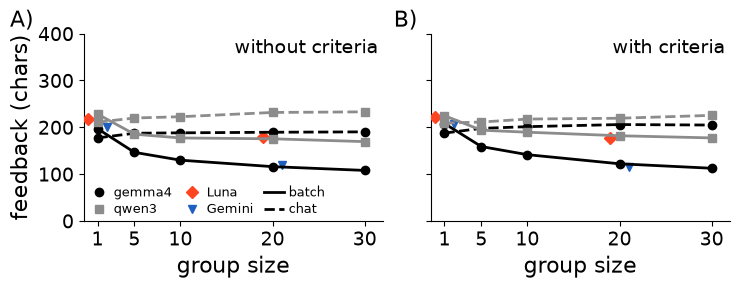

In [44]:
# 5) plot: A) without, B) with criteria; x = group size, y = mean feedback length
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, sharey=True)
for i, (ax, crit, note) in enumerate(zip(axes, (False, True), ("without criteria", "with criteria"))):
    for (model, workflow), grp in feedback[feedback.criteria == crit].groupby(["model", "workflow"]):
        means = grp.groupby("size").chars.mean()
        color, marker = MODEL_COLOR[model], MODEL_MARKER[model]
        offset = {"Luna": -1.0, "Gemini": 1.0}.get(model, 0.0)
        style = marker if model in ("Luna", "Gemini") else ("-" if workflow == "batch" else "--") + marker
        ax.plot(means.index + offset, means.values, style, color=color, linewidth=2.0, markersize=6, zorder=3)
    ax.set_xticks([1, 5, 10, 20, 30], ["1", "5", "10", "20", "30"], fontsize=TICK)
    ax.set_xlim(-0.5, 32)
    ax.set_ylim(0, 400)
    ax.set_xlabel("group size", fontsize=LABEL)
    if i == 0:
        ax.set_ylabel("feedback (chars)", fontsize=LABEL)
        ax.set_yticks([0, 100, 200, 300, 400], ["0", "100", "200", "300", "400"], fontsize=TICK)
    else:
        ax.tick_params(axis="y", labelsize=0)
    ax.text(31.5, 390, note, fontsize=TICK, ha="right", va="top")
    ax.text(-8.5 if i == 0 else -4.5, 415, "AB"[i] + ")", fontsize=LABEL)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].legend(handles=handles, loc="lower left", fontsize=9, frameon=False, ncol=3, handlelength=1.6,
               columnspacing=0.8, labelspacing=0.2, handletextpad=0.4, borderaxespad=0.0)
save_figure(fig, "Feedback_lengthVsGroupSize_allModels")
plt.show()

**6) What the figure shows.**

- **Batch: feedback shrinks with group size.** gemma4 from 197 to 108 characters without criteria (−45 %)
  and from 208 to 113 with criteria; Gemini from about 205 alone to about 118 in groups of 20; qwen3 and Luna
  lose 20–25 %.
- **Chat: feedback stays at full length** or grows slightly (gemma4 177 → 190, qwen3 211 → 233 without
  criteria). Each student gets their own answer turn.

## 10. Lost and duplicated students (SI)

**Idea.** In a batch, the model has to return one grading per student; in a chat, one per turn. A student
is lost if no valid grade comes back for the student's code, duplicated if the same code is graded twice.
Per model × workflow × group size (random groups of the main experiment, all criteria conditions), plus
the pilot with all 60 texts of a task in one prompt / one conversation (gemma4 only).

In [45]:
# 2) compute: share of lost and duplicated students per call / conversation
LOST_SOURCES = CONTEXT_SOURCES + [("gemma4", "batch", "batch_pilot_gemma4-26b.jsonl"),
                                  ("gemma4", "chat", "seq_seqpilot_gemma4-26b.jsonl")]
lost_rows = []
for label, workflow, fname in LOST_SOURCES:
    for line in open(RESULTS / fname, encoding="utf-8"):
        r = json.loads(line)
        m = re.fullmatch(r"random(\d+)|all(60)", r["design"])
        if not m or ("pilot" in fname and r["design"] != "all60") or r.get("error") is not None:
            continue
        size = int(m.group(1) or m.group(2))
        graded = {tid for tid, g in graded_students(r)}
        dup = len((r.get("diagnostics") or {}).get("duplicates", [])) if "turns" not in r else 0
        lost_rows.append({"model": label, "workflow": workflow, "size": size, "pilot": "pilot" in fname,
                          "expected": size, "lost": size - len(graded), "duplicated": dup})
lost = pd.DataFrame(lost_rows)
lost_summary = (lost.groupby(["model", "workflow", "size", "pilot"])
                .agg(calls=("expected", "size"), students=("expected", "sum"), lost=("lost", "sum"),
                     duplicated=("duplicated", "sum")).reset_index())
lost_summary["lost_pct"] = 100 * lost_summary.lost / lost_summary.students
lost_summary["dup_pct"] = 100 * lost_summary["duplicated"] / lost_summary.students
lost_summary

,model,workflow,size,pilot,calls,students,lost,duplicated,lost_pct,dup_pct
0,Gemini,batch,20,False,216,4320,0,0,0,0
1,Luna,batch,20,False,216,4320,0,0,0,0
2,gemma4,batch,5,False,864,4320,5,0,0.116,0
3,gemma4,batch,10,False,432,4320,4,0,0.0926,0
4,gemma4,batch,20,False,216,4320,1,0,0.0231,0
5,gemma4,batch,30,False,144,4320,7,4,0.162,0.0926
6,gemma4,batch,60,True,4,240,8,7,3.33,2.92
7,gemma4,chat,5,False,864,4320,1,0,0.0231,0
8,gemma4,chat,10,False,432,4320,1,0,0.0231,0
9,gemma4,chat,20,False,216,4320,1,0,0.0231,0


In [46]:
# 3) save
lost_summary.to_pickle(DATA / "lost_students.pkl")

In [47]:
# 4) load
lost_summary = pd.read_pickle(DATA / "lost_students.pkl")

In [48]:
# 5) SI table (LaTeX)
t = lost_summary.sort_values(["pilot", "model", "workflow", "size"])
lines = [r"\begin{tabular}{llrrrrr}", r"\toprule",
         r"Model & Workflow & Group size & Calls & Students & Lost (\%) & Duplicated (\%) \\", r"\midrule"]
for _, r in t.iterrows():
    size = f"{r['size']} (pilot)" if r.pilot else f"{r['size']}"
    lines.append(f"{r.model} & {r.workflow} & {size} & {r.calls} & {r.students} & {r.lost_pct:.2f} & "
                 f"{r.dup_pct:.2f} \\\\")
lines += [r"\bottomrule", r"\end{tabular}"]
(TABLES / "Table_lostStudents.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("saved", TABLES / "Table_lostStudents.tex")

saved paper/tables/Table_lostStudents.tex


**6) What the table shows.**

- **Up to 30 students, lost and duplicated students are negligible:** at most 0.16 % lost and 0.09 %
  duplicated in any condition; the commercial models lost none.
- **60 students in one prompt (pilot, gemma4):** 3.3 % lost and 2.9 % duplicated; the chat workflow with
  60 students lost none. Large batches become unreliable in a way the teacher may not notice.

## 11. Prompt format and the preceding student (SI)

**Idea (a) prompt format.** The local models graded every text alone twice: in the batch format (task in the
user message) and in the chat format (task in the system prompt, like a Gem). Nothing else differs. Per text:
mean grade in chat format minus mean grade in batch format. Paired two-sided Wilcoxon test over texts, Holm
over the 4 model × criteria conditions, bootstrap CI of the mean shift. This is why every workflow is
compared with the grade alone in its own format.

**Idea (b) preceding student.** In random groups, the order is random, so the intended grade of the
preceding student is independent of the current text. Per graded student (position ≥ 2): change = grade in
the group minus the same model's mean grade alone. Spearman correlation between the change and the intended
grade of the preceding student, per model × workflow × criteria, Holm-corrected. A negative correlation is a
contrast effect with the immediately preceding student.

**Control.** A weak preceding student also makes the rest of the group slightly weaker, so part of the correlation could come from the group composition. Control: the same correlation with the intended grade of the *following* student. In the chat workflow the model has not yet seen the following student, so any correlation there is composition (or sampling), not order. In the batch workflow the model sees all students at once.

In [49]:
# 2) compute: (a) shift between the two alone formats, (b) change vs. the preceding student's intended grade
fmt_rows = []
for model in ("gemma4", "qwen3"):
    alone_fmt = {}
    for workflow, fname in (("batch", f"batch_main_{'gemma4-26b' if model == 'gemma4' else 'qwen3-30b-a3b'}.jsonl"),
                            ("chat", f"seq_main_{'gemma4-26b' if model == 'gemma4' else 'qwen3-30b-a3b'}.jsonl")):
        runs = defaultdict(list)
        for line in open(RESULTS / fname, encoding="utf-8"):
            r = json.loads(line)
            if r["design"] == "single_code":
                for tid, g in graded_students(r):
                    runs[(r["criteria"], tid)].append(NUM[g])
        alone_fmt[workflow] = {k: np.mean(v) for k, v in runs.items()}
    for crit in (False, True):
        keys = [k for k in alone_fmt["batch"] if k[0] == crit and k in alone_fmt["chat"]]
        diff = np.array([alone_fmt["chat"][k] - alone_fmt["batch"][k] for k in keys])
        lo, hi = boot_ci(diff)
        fmt_rows.append({"model": model, "criteria": crit, "texts": len(diff), "shift": diff.mean(), "lo": lo, "hi": hi,
                         "abs_diff": np.abs(diff).mean(), "p": stats.wilcoxon(diff).pvalue})
prompt_format = pd.DataFrame(fmt_rows)
prompt_format["p_holm"] = holm_correct(prompt_format.p)

prev_rows = []
for label, workflow, fname in CONTEXT_SOURCES:
    recs = [json.loads(l) for l in open(RESULTS / fname, encoding="utf-8")]
    alone = defaultdict(list)
    for r in recs:
        if r["design"] == "single_code":
            for tid, g in graded_students(r):
                alone[(r["criteria"], tid)].append(NUM[g])
    for r in recs:
        if not re.fullmatch(r"random\d+", r["design"]) or r.get("error") is not None:
            continue
        order = sorted((s["position"], s["text_id"]) for s in (r["turns"] if "turns" in r else r["students"]))
        prev_of = {tid: order[i - 1][1] for i, (_, tid) in enumerate(order) if i > 0}
        next_of = {tid: order[i + 1][1] for i, (_, tid) in enumerate(order) if i < len(order) - 1}
        for tid, g in graded_students(r):
            ref = alone.get((r["criteria"], tid))
            if ref:
                prev_rows.append({"model": label, "workflow": workflow, "criteria": r["criteria"],
                                  "change": NUM[g] - np.mean(ref),
                                  "prev_intended": INTENDED[prev_of[tid]] if tid in prev_of else np.nan,
                                  "next_intended": INTENDED[next_of[tid]] if tid in next_of else np.nan})
preceding = pd.DataFrame(prev_rows)
pre_rows = []
for (model, workflow, crit), both in preceding.groupby(["model", "workflow", "criteria"]):
    grp = both.dropna(subset=["prev_intended"])
    nxt = both.dropna(subset=["next_intended"])
    rho, p = stats.spearmanr(grp.change, grp.prev_intended)
    rho_next, p_next = stats.spearmanr(nxt.change, nxt.next_intended)
    low = grp[grp.prev_intended <= 1].change.mean()          # preceding text F or E
    high = grp[grp.prev_intended >= 4].change.mean()         # preceding text B or A
    pre_rows.append({"model": model, "workflow": workflow, "criteria": crit, "gradings": len(grp), "rho": rho,
                     "after_low": low, "after_high": high, "difference": low - high, "p": p,
                     "rho_next": rho_next, "p_next": p_next})
preceding_tests = pd.DataFrame(pre_rows)
preceding_tests["p_holm"] = holm_correct(preceding_tests.p)
preceding_tests["p_next_holm"] = holm_correct(preceding_tests.p_next)
display(prompt_format.round(3))
preceding_tests.round(3)

,model,criteria,texts,shift,lo,hi,abs_diff,p,p_holm
0,gemma4,False,720,0.308,0.272,0.345,0.318,0,0
1,gemma4,True,720,0.104,0.077,0.133,0.157,0,0
2,qwen3,False,720,0.187,0.155,0.219,0.362,0,0
3,qwen3,True,720,0.031,-0,0.061,0.254,0.052,0.052


,model,workflow,criteria,gradings,rho,after_low,after_high,difference,p,rho_next,p_next,p_holm,p_next_holm
0,Gemini,batch,False,2052,-0.085,-0.203,-0.374,0.171,0,-0.027,0.229,0,1
1,Gemini,batch,True,2052,-0.088,-0.402,-0.566,0.164,0,-0.041,0.066,0,0.594
2,Luna,batch,False,2052,-0.047,0.561,0.453,0.109,0.033,-0.028,0.205,0.066,1
3,Luna,batch,True,2052,-0.007,0.093,0.098,-0.005,0.735,0.005,0.817,0.735,1
4,gemma4,batch,False,7805,-0.15,0.271,0.042,0.229,0,-0.026,0.02,0,0.246
5,gemma4,batch,True,7802,-0.142,-0.246,-0.472,0.226,0,-0.023,0.045,0,0.499
6,gemma4,chat,False,7810,-0.122,0.145,-0.032,0.177,0,0.009,0.45,0,1
7,gemma4,chat,True,7811,-0.089,-0.097,-0.243,0.146,0,0.004,0.715,0,1
8,qwen3,batch,False,7812,-0.199,0.526,0.127,0.4,0,-0.021,0.059,0,0.588
9,qwen3,batch,True,7812,-0.14,0.308,0.03,0.278,0,-0.003,0.773,0,1


In [50]:
# 3) save
prompt_format.to_pickle(DATA / "prompt_format_shift.pkl")
preceding_tests.to_pickle(DATA / "preceding_student_tests.pkl")

In [51]:
# 4) load
prompt_format = pd.read_pickle(DATA / "prompt_format_shift.pkl")
preceding_tests = pd.read_pickle(DATA / "preceding_student_tests.pkl")

In [52]:
# 5) SI tables (LaTeX)
lines = [r"\begin{tabular}{llrccc}", r"\toprule",
         r"Model & Criteria & Texts & Shift (chat $-$ batch format) & Mean $|$difference$|$ & $p_\mathrm{Holm}$ \\",
         r"\midrule"]
for _, r in prompt_format.sort_values(["criteria", "model"]).iterrows():
    lines.append(f"{r.model} & {'with' if r.criteria else 'without'} & {r.texts} & "
                 f"{r['shift']:+.2f} [{r.lo:+.2f}, {r.hi:+.2f}] & {r.abs_diff:.2f} & {sci(r.p_holm)} \\\\")
lines += [r"\bottomrule", r"\end{tabular}"]
(TABLES / "Table_promptFormat.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

lines = [r"\begin{tabular}{llcrcccccc}", r"\toprule",
         r" & & & & & & \multicolumn{2}{c}{Preceding student} & \multicolumn{2}{c}{Following student} \\",
         r"\cmidrule(lr){7-8}\cmidrule(lr){9-10}",
         r"Criteria & Model & Workflow & Gradings & After F, E & After B, A & $\rho$ & $p_\mathrm{Holm}$ & $\rho$ & $p_\mathrm{Holm}$ \\", r"\midrule"]
prev = None
for _, r in preceding_tests.sort_values(["criteria", "model", "workflow"]).iterrows():
    if prev is not None and r.criteria != prev:
        lines.append(r"\midrule")
    prev = r.criteria
    lines.append(f"{'with' if r.criteria else 'without'} & {r.model} & {r.workflow} & {r.gradings} & "
                 f"{r.after_low:+.2f} & {r.after_high:+.2f} & {r.rho:+.2f} & {pfmt(r.p_holm)} & "
                 f"{r.rho_next:+.2f} & {pfmt(r.p_next_holm)} \\\\")
lines += [r"\bottomrule", r"\end{tabular}"]
(TABLES / "Table_precedingStudent.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("saved Table_promptFormat.tex and Table_precedingStudent.tex")

saved Table_promptFormat.tex and Table_precedingStudent.tex


**6) What the tables show.**

- **Prompt format alone shifts grades:** the same text graded alone gets a higher grade when the task is in
  the system prompt (chat format) than in the user message (batch format): gemma4 +0.31 / +0.10 grades
  (without / with criteria), qwen3 +0.19 / +0.03 (n.s. with criteria). Hence each workflow is compared with
  the grade alone in its own format.
- **The preceding student matters:** after a weak student (F, E) a text receives a higher grade than after a
  strong one (B, A), by 0.15–0.40 grades for gemma4, qwen3 and Gemini (ρ −0.08 to −0.20, all p_Holm ≤ 3.6·10⁻⁴),
  in both workflows. Luna shows no such effect.
- **Control: the following student does not matter** (ρ −0.04 to +0.01, all n.s.), not even in batch, where
  the model sees all students at once. The effect is tied to the order, not to the group composition alone.

## 12. Models, inference settings and run-to-run noise (SI tables)

**Idea.** (a) The settings of every request, read from the result records rather than from the scripts:
model identifier, model digest (local models), reasoning setting, context window, number of
successful requests and how many needed a retry. (b) Run-to-run noise of each model when grading a text alone,
per prompt format and criteria condition: share of texts that received the same grade in every run, and the
mean absolute deviation of one run from the mean of the other runs (the noise of Table S4).

In [53]:
# 2) compute: (a) settings per result file, (b) noise per model x prompt format x criteria
SETTING_SOURCES = [  # (model, workflow / prompt format, file)
    ("gemma4", "alone, heading Elev 1", "anon_inferno_gemma4-26b_nothink.jsonl"),
    ("gemma4", "alone and batch", "batch_main_gemma4-26b.jsonl"),
    ("gemma4", "alone and chat", "seq_main_gemma4-26b.jsonl"),
    ("qwen3", "alone, heading Elev 1", "anon_inferno_qwen3-30b-a3b_think-off.jsonl"),
    ("qwen3", "alone and batch", "batch_main_qwen3-30b-a3b.jsonl"),
    ("qwen3", "alone and chat", "seq_main_qwen3-30b-a3b.jsonl"),
    ("Luna", "alone and batch", "or_ormain_openai-gpt-6-luna.jsonl"),
    ("Gemini", "alone and batch", "or_ormain_google-gemini-3.1-flash-lite.jsonl"),
]
set_rows = []
for label, workflow, fname in SETTING_SOURCES:
    recs = [json.loads(l) for l in open(RESULTS / fname, encoding="utf-8")]
    ok = [r for r in recs if (r.get("turns") is not None) or (r.get("error") is None)]
    if "turns" in recs[0]:
        requests = [t for r in ok for t in r["turns"] if t.get("grade")]
        retried = sum(1 for t in requests if (t.get("attempts") or 1) > 1)
    else:
        requests = ok
        retried = sum(1 for r in ok if (r.get("attempts") or 1) > 1)
    if "reasoning_setting" in recs[0]:
        reasoning = "off" if all(r["reasoning_setting"] == {"enabled": False} for r in recs) else "mixed"
        reasoning += ", 0 tokens" if all(not r.get("reasoning_tokens") for r in ok) else ""
    else:
        reasoning = "off" if all(r.get("think") is False for r in recs) else "mixed"
    ctx = sorted({r["num_ctx"] for r in recs if r.get("num_ctx")})
    predict = {("500 + 450n" if r.get("num_predict") == 500 + 450 * int(r["batch_size"]) else r.get("num_predict"))
               for r in recs if "num_predict" in r or "tag" in r} if "seq_main" not in fname else {recs[0]["num_predict"]}
    if "or_ormain" in fname:
        predict = {"500 + 450n"}                          # max_tokens in run_openrouter.py (not stored per record)
    set_rows.append({"model": label, "identifier": recs[0]["model"], "workflow": workflow,
                     "digest": (recs[0].get("model_digest") or "")[:12] or "--",
                     "reasoning": reasoning, "context": "/".join(f"{c // 1024}k" for c in ctx) or "--",
                     "output_limit": ", ".join(str(p) for p in sorted(predict, key=str)) if predict else "none",
                     "requests": len(requests), "retried": retried})
settings = pd.DataFrame(set_rows)

NOISE_SOURCES = [("gemma4", "batch format", "batch_main_gemma4-26b.jsonl"), ("gemma4", "chat format", "seq_main_gemma4-26b.jsonl"),
                 ("qwen3", "batch format", "batch_main_qwen3-30b-a3b.jsonl"), ("qwen3", "chat format", "seq_main_qwen3-30b-a3b.jsonl"),
                 ("Luna", "batch format", "or_ormain_openai-gpt-6-luna.jsonl"),
                 ("Gemini", "batch format", "or_ormain_google-gemini-3.1-flash-lite.jsonl")]
noise_rows = []
for label, fmt, fname in NOISE_SOURCES:
    alone = defaultdict(list)
    for line in open(RESULTS / fname, encoding="utf-8"):
        r = json.loads(line)
        if r["design"] == "single_code":
            for tid, g in graded_students(r):
                alone[(r["criteria"], tid)].append(NUM[g])
    for crit in (False, True):
        runs = [v for (c, _), v in alone.items() if c == crit and len(v) >= 2]
        noise_rows.append({"model": label, "format": fmt, "criteria": crit, "texts": len(runs),
                           "runs": int(np.median([len(v) for v in runs])),
                           "identical": np.mean([len(set(v)) == 1 for v in runs]),
                           "noise": np.mean([np.mean([abs(v[i] - loo_mean(v, i)) for i in range(len(v))]) for v in runs])})
noise_table = pd.DataFrame(noise_rows)
display(settings)
noise_table.round(3)

,model,identifier,workflow,digest,reasoning,context,output_limit,requests,retried
0,gemma4,gemma4:26b,"alone, heading Elev 1",5571076f3d70,off,8k,none,4320,21
1,gemma4,gemma4:26b,alone and batch,5571076f3d70,off,8k/16k,500 + 450n,6408,5
2,gemma4,gemma4:26b,alone and chat,5571076f3d70,off,16k,1024,30236,20
3,qwen3,qwen3:30b-a3b,"alone, heading Elev 1",ad815644918f,off,8k,1024,4320,4
4,qwen3,qwen3:30b-a3b,alone and batch,ad815644918f,off,8k/16k,500 + 450n,6408,16
5,qwen3,qwen3:30b-a3b,alone and chat,ad815644918f,off,16k,1024,30238,61
6,Luna,openai/gpt-6-luna,alone and batch,--,"off, 0 tokens",--,500 + 450n,3528,0
7,Gemini,google/gemini-3.1-flash-lite,alone and batch,--,"off, 0 tokens",--,500 + 450n,3528,0


,model,format,criteria,texts,runs,identical,noise
0,gemma4,batch format,False,720,3,0.815,0.13
1,gemma4,batch format,True,720,3,0.886,0.081
2,gemma4,chat format,False,720,3,0.868,0.095
3,gemma4,chat format,True,720,3,0.904,0.076
4,qwen3,batch format,False,720,3,0.488,0.362
5,qwen3,batch format,True,720,3,0.649,0.264
6,qwen3,chat format,False,720,3,0.4,0.445
7,qwen3,chat format,True,720,3,0.635,0.289
8,Luna,batch format,False,720,2,0.881,0.214
9,Luna,batch format,True,720,2,0.875,0.146


In [54]:
# 3) save
settings.to_pickle(DATA / "inference_settings.pkl")
noise_table.to_pickle(DATA / "noise_per_model.pkl")

In [55]:
# 4) load
settings = pd.read_pickle(DATA / "inference_settings.pkl")
noise_table = pd.read_pickle(DATA / "noise_per_model.pkl")

In [56]:
# 5) SI tables (LaTeX)
lines = [r"\begin{tabular}{llllllr}", r"\toprule",
         r"Model & Identifier & Workflows & Digest & Reasoning & Context & Requests (retried) \\",
         r"\midrule"]
for _, r in settings.iterrows():
    lines.append(f"{r.model} & \\texttt{{{r.identifier}}} & {r.workflow} & \\texttt{{{r.digest}}} & {r.reasoning} & "
                 f"{r.context} & {r.requests:,} ({r.retried}) \\\\")
lines += [r"\bottomrule", r"\end{tabular}"]
(TABLES / "Table_inferenceSettings.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

lines = [r"\begin{tabular}{llcrrcc}", r"\toprule",
         r"Model & Prompt format & Criteria & Texts & Runs & Same grade in all runs & $|\Delta|$ alone \\", r"\midrule"]
for _, r in noise_table.sort_values(["criteria", "model", "format"]).iterrows():
    lines.append(f"{r.model} & {r.format} & {'with' if r.criteria else 'without'} & {r.texts} & {r.runs} & "
                 f"{100 * r.identical:.0f}\\,\\% & {r.noise:.2f} \\\\")
lines += [r"\bottomrule", r"\end{tabular}"]
(TABLES / "Table_noisePerModel.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("saved Table_inferenceSettings.tex and Table_noisePerModel.tex")

saved Table_inferenceSettings.tex and Table_noisePerModel.tex


**6) What the tables show.**

- **Settings (from the records):** reasoning was off in every request; the commercial models produced no
  reasoning tokens. All 3,528 planned requests per commercial model succeeded; fewer than 1 % of the local
  requests needed a retry. The context window was never exceeded.
- **Noise:** gemma4, Gemini and Luna gave the same grade in every run to 82–93 % of the texts (|Δ| 0.08–0.21);
  qwen3 only to 40–65 % (|Δ| 0.26–0.44). Criteria reduce the noise of gemma4 and qwen3.